<table style="background-color: transparent;">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1">Computación Cuántica</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">2027-1</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="6" color="#6366F1">Laboratorio 5: Algoritmos Cuánticos III</font></td>
    </tr>
</table>

---
<h3>Autores:</h3>

<h4>
- Naomi Reyes Granados<br>
- Sebastián González Juárez<br>
- Owen Charbel Sam Ramírez <br>
- Angel Carmona Zavaleta
</h4>

<p>
Este notebook está adaptado del material desarrollado originalmente por
<b>Claudia Zendejas Morales</b>, el cual constituye la base principal de este
notebook. Sobre dicho material se realizaron modificaciones, ampliaciones y
adaptaciones para su uso en esta clase.
</p>

---

## Contenido

1. [Algoritmo de Bernstein–Vazirani](#1)
   1. [El problema](#1.1)
   2. [Solución clásica](#1.2)
   3. [Solución cuántica](#1.3)
2. [Algoritmo de Grover](#2)
   1. [Inversión sobre la media](#2.1)
   2. [Algoritmo de búsqueda de Grover](#2.2)
   4. [Ejemplos de uso](#2.3)
3. [Práctica 5](#4)

<a id="1"></a>
# 1. Algoritmo de Bernstein–Vazirani

<a id="1.1"></a>
## 1.1. El problema

Dada una función $f:\{0,1\}^n \rightarrow \{0,1\}$, que se define como $ f(\mathbf{x}) = x \cdot s $, se busca determinar la cadena secreta (secuencia de bits) $s$.

Donde $x \cdot s$ el producto punto de las cadenas de bits módulo 2. Por ejemplo, si $x = 1000$ y $s = 1010$, entonces

$$x\cdot s = 1\cdot 1 + 0\cdot 0 + 0\cdot 1 + 0 \cdot0 = 1 \pmod 2 = 1$$

Esto podría parecer un problema creado artificialmente, porque lo es. Fue diseñado específicamente para resolverse utilizando una computadora cuántica con el fin de demostrar que puede haber ventajas en el uso de algoritmos cuánticos sobre los algoritmos clásicos.

Por ejemplo, si la función $f$ está definida como:

\begin{align*}
	f(00)&=0\\
	f(01)&=1\\
	f(10)&=0\\
	f(11)&=1\\
	\end{align*}

En este ejemplo, la cadena secreta está definida como $s=01$, por lo que tenemos:

\begin{align*}
f(00)=00\cdot 01 = 0\\
f(01)=01\cdot 01 = 1\\
f(10)=10\cdot 01 = 0\\
f(11)=11\cdot 01 = 1
\end{align*}

Así, el operador unitario $U_f$ toma la forma:

$$ U_f: \ket{x}\ket{y} \mapsto \ket{x}\ket{y \oplus ( x \cdot s)} $$

<a id="1.2"></a>
## 1.2. Solución clásica

Se necesitan $n$ consultas para determinar la cadena secreta $s$.

<div class="alert alert-block alert-info">
<strong>Ejemplo</strong>:

Consideremos $n=4$ y las siguientes consultas a $f$:

\begin{align*}
f(1000) &= s_1\cdot 1 + s_2\cdot 0 + s_3\cdot 0 + s_4\cdot 0 = s_1\\
f(0100) &= s_1\cdot 0 + s_2\cdot 1 + s_3\cdot 0 + s_4\cdot 0 = s_2\\
f(0010) &= s_1\cdot 0 + s_2\cdot 0 + s_3\cdot 1 + s_4\cdot 0 = s_3\\
f(0001) &= s_1\cdot 0 + s_2\cdot 0 + s_3\cdot 0 + s_4\cdot 1 = s_4\\
\end{align*}

Con esos $4$ _queries_ se puede determinar cada bit de la cadena $s=s_1s_2s_3s_4$.

<a id="1.3"></a>
## 1.3. Solución cuántica

Con la solución cuántica se necesitará **consultar la función $f$ una sola vez**.

### Algoritmo

El algoritmo es el mismo que en el caso de _Deutsch – Jozsa_, es decir, se realizan los mismos pasos, lo que cambia es la implementación de $U_f$, que nos debe dar la operación $ U_f: \ket{x}\ket{y} \mapsto \ket{x}\ket{y \oplus ( x \cdot s)} $, es decir, $U_f$ debe contener codificada la cadena de bits secreta $s$.

Construimos un circuito con $n+1$ qubits.

- Establecer el qubit auxiliar $n+1$ en el estado $\ket{-}$ aplicando las compuertas $X$ y $H$.
- Aplicar $H$ a los primeros $n$ qubits.
- Aplicar $U_f$.
- Aplicar $H$ a los primeros $n$ qubits.
- Medir los primeros $n$ qubits para obtener $s$.

#### Pasos

<div align="center">
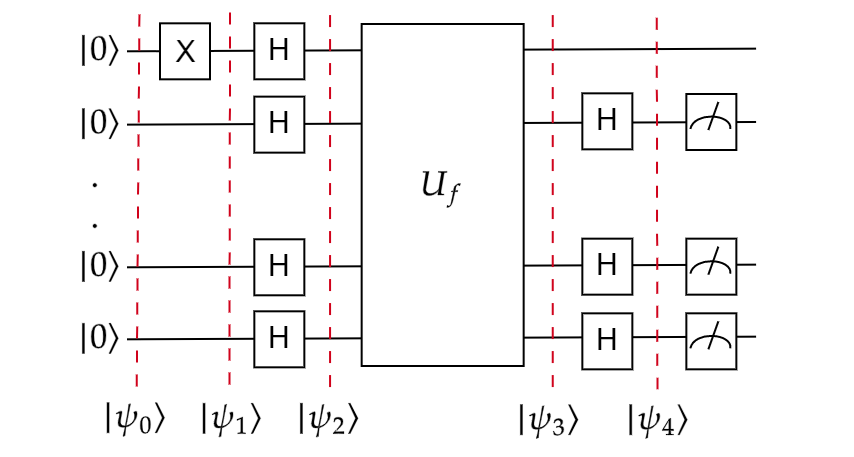

### Oráculo $U_f$

En el algoritmo de Bernstein-Vazirani, el oráculo $U_f$ representa una función
determinada por una cadena secreta $s$.

La función está definida como:

$$f(x)=s\cdot x \pmod 2$$

Para construir el oráculo, se aplican compuertas CNOT desde los cúbits de entrada
hacia el cúbit auxiliar en aquellas posiciones donde la cadena secreta $s$ contiene un 1.


In [1]:
!pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 51.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.2 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.1 MB/s eta 0:00:00


In [2]:
!pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.6 MB/s eta 0:00:00


In [3]:
import random
from qiskit import QuantumCircuit

def oraculo_Uf(n):
    # Generamos una cadena secreta s de n bits
    s = ''.join(random.choice('01') for _ in range(n))

    # n qubits de entrada + 1 qubit auxiliar
    Uf = QuantumCircuit(n + 1, name="Uf")

    # Aplicamos CNOT donde s contiene un 1
    for i, bit in enumerate(s):
        if bit == '1':
            Uf.cx(i, n)

    return Uf, s

Cadena secreta s = 0100


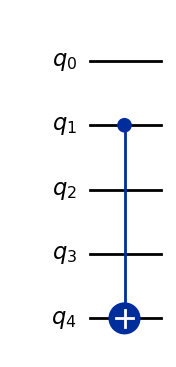

In [4]:
Uf, s = oraculo_Uf(4)

print("Cadena secreta s =", s)

Uf.draw("mpl")

**Paso 1**

Se preparan dos registros cuánticos. El primero en un registro de $n$ qubits inicializado en $\ket{0}^{\otimes n}$, el segundo registro es un qubit inicializado en $\ket{1}$,

$$\ket{\psi_1} = \ket{0}^{\otimes n} \, \ket{1}$$

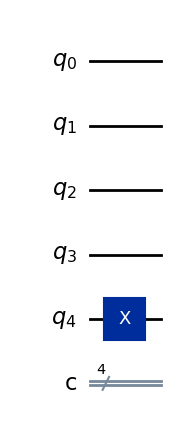

In [5]:
from qiskit import QuantumCircuit

n = 4

# n qubits de entrada + 1 qubit auxiliar
qc = QuantumCircuit(n + 1, n)

# El último qubit es el auxiliar y debe iniciar en |1>
qc.x(n)

qc.draw("mpl")

**Paso 2**

Se aplican compuertas Hadamard a cada qubit,

$$\ket{\psi_2} = \frac{1}{\sqrt{2^n}}\sum_{x=0}^{2^n-1} \ket{x} \otimes \ket{-}$$

$$\ket{\psi_2}=\frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1} \, \ket{x} \, \big(\ket{0}-\ket{1}\big)$$

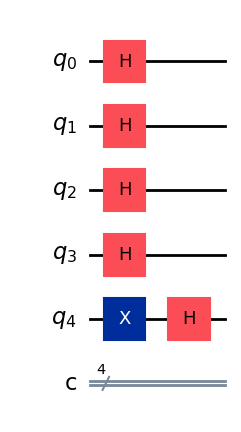

In [6]:
# Aplicamos Hadamard a todos los qubits
for i in range(n + 1):
    qc.h(i)

# Mostramos el avance del circuito
qc.draw("mpl")

**Paso 3**

De ahora en adelante podemos ignorar el qubit auxiliar y centrarnos en los qubits de entrada. Después de aplicar $U_f$ obtenemos el estado:

$$ \ket{\psi_{3,r_1}}= \frac{1}{\sqrt{2^n}} \sum_{x=0}^{2^n-1} (-1)^{f(x)} \ket{x} $$

Reemplacemos $f(x) = x \cdot s$ y reescribamos el estado de la siguiente manera:

$$ \ket{\psi_{3,r_1}} = \frac{1}{\sqrt{2^n}} \sum_{x=0}^{2^n-1} (-1)^{x \cdot s} \ket{x} $$

Cadena secreta s = 0100


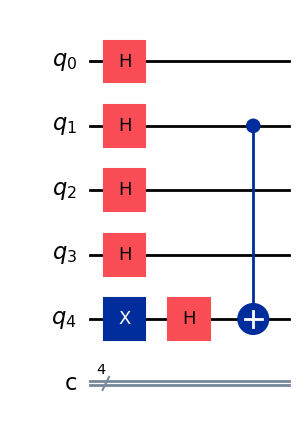

In [7]:
# Mostramos la cadena secreta generada anteriormente
print("Cadena secreta s =", s)

# Agregamos el mismo oráculo al circuito principal
qc.compose(Uf, qubits=range(n + 1), inplace=True)

# Mostramos el circuito construido
qc.draw("mpl")

<div class="alert alert-block alert-success">
<strong>Recordatorio</strong>:

$$ H^{\otimes n} \ket{x} = \frac{1}{\sqrt{2^n}} \sum_{x=0}^{2^n-1} (-1)^{x \cdot z} \ket{z}$$

También sabemos que el operador $H^{\otimes n}$ es su propio inverso. Por lo tanto, podemos decir que

$$H^{\otimes n}\ket{a} = \ket{b} \Longleftrightarrow H^{\otimes n}\ket{b} = \ket{a}$$

Entonces, de hecho, $\ket{\psi_3}$ es el estado obtenido después de aplicar $H^{\otimes n}$ al estado $\ket{s}$.

**Paso 4**

Por lo tanto, después de aplicar $H^{\otimes n}$ a los qubits de entrada, obtenemos el estado final como

$$\ket{\psi_{4,r_1}} = \ket{s}.$$

Medimos los primeros $n$ qubits y observamos la cadena $s$ con probabilidad $1$.

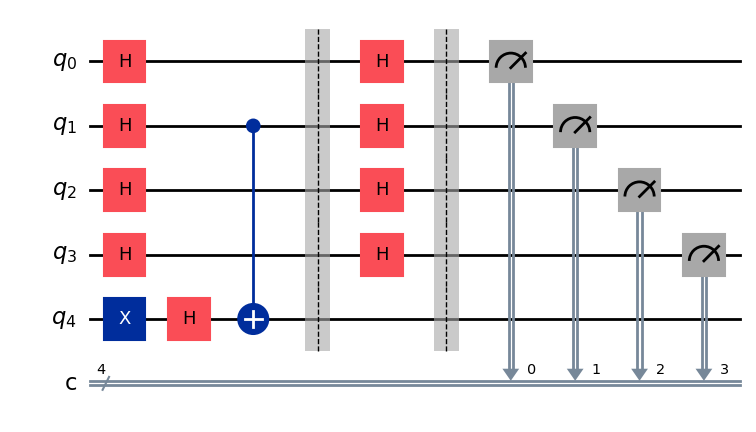

In [8]:
# Separamos visualmente el oráculo de la etapa final
qc.barrier()

# Aplicamos Hadamard a los qubits de entrada
for i in range(n):
    qc.h(i)

# Separamos las Hadamard de las mediciones
qc.barrier()

# Medimos los qubits de entrada
qc.measure(range(n), range(n))

# Mostramos el circuito completo
qc.draw("mpl")

### Implementación en Qiskit

La implementación es como la del algoritmo de _Deutsch – Jozsa_, ya que son los mismos pasos, salvo el contenido de $U_f$.

In [9]:
from qiskit import QuantumCircuit

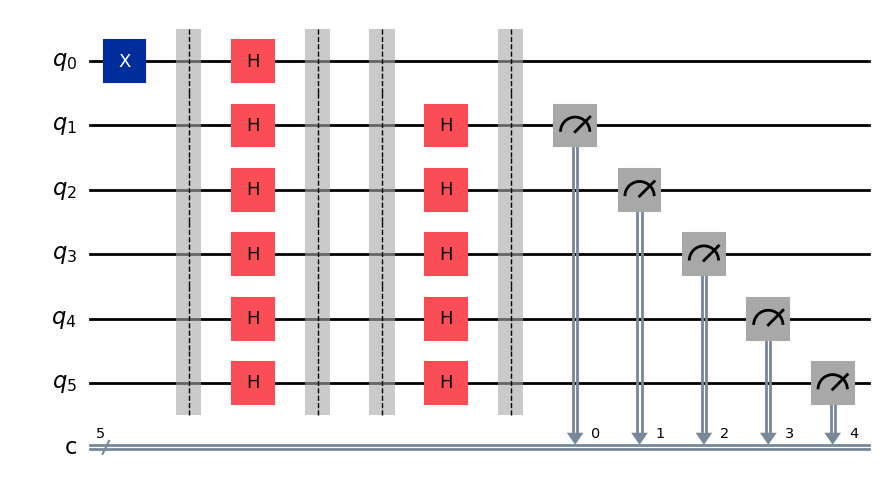

In [10]:
n = 5                                        # longitud de 's'

bv_circuit = QuantumCircuit(n+1, n)          # n+1=6 qubits, n=5 bits clásicos

##########
# Paso 1 #
##########

bv_circuit.x(0)                              # colocar el qubit q0 (segundo registro) en el estado |1>
bv_circuit.barrier()


##########
# Paso 2 #
##########

# Aplicar las compuertas H al primer registro
for qubit in range(1, n + 1):
    bv_circuit.h(qubit)

# Aplicar H al segundo registro, H|1> = |->
bv_circuit.h(0)

bv_circuit.barrier()


##########
# Paso 3 #
##########

# Aplicar U_f

bv_circuit.barrier()      # s = 00000, es decir, no se aplican compuertas


##########
# Paso 4 #
##########

# Aplicar nuevamente compuertas H al primer registro
for qubit in range(1, n + 1):
    bv_circuit.h(qubit)

bv_circuit.barrier()


##########
# Medir  #
##########

# Agregamos mediciones al primer registro
for i in range(n):
    bv_circuit.measure(i + 1, i)


bv_circuit.draw('mpl')

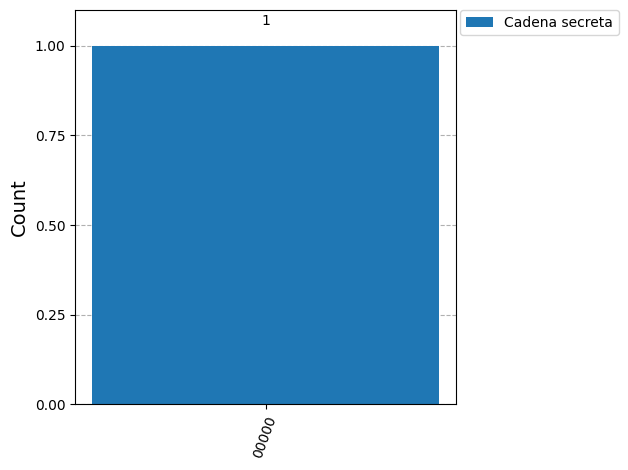

In [11]:
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram

sim_basic = BasicSimulator()                       # usamos el simulador básico

# ejecutar el circuito, una sola vez es suficiente
job_sampler = sim_basic.run(bv_circuit, shots=1)

conteos = job_sampler.result().get_counts()        # obtener los conteos

legend = ["Cadena secreta"]
plot_histogram([conteos], legend=legend)

---
## Mini actividad. Comparación clásica-cuántica del algoritmo de Bernstein–Vazirani

**Objetivo:** Recuperar una misma cadena secreta mediante procedimientos clásico y cuántico, y comparar el número de consultas al oráculo.

Considera una cadena secreta de 5 bits y la función $f(x)=s\cdot x\bmod 2$.

Ejecuta la siguiente celda sin modificarla. Ambas funciones utilizan la misma cadena secreta.

In [12]:
from qiskit import QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator

# Define la cadena secreta y el contador de consultas clásicas.
s = "10110"
n = len(s)
consultas_clasicas = 0

# Evalúa la función clásica y registra cada consulta realizada.
def f(x):
    global consultas_clasicas
    consultas_clasicas += 1
    return sum(int(a) * int(b) for a, b in zip(s, x)) % 2

# Construye el oráculo cuántico correspondiente a la misma función.
def oraculo():
    uf = QuantumCircuit(n + 1)
    for i, bit in enumerate(s):
        if bit == "1":
            uf.cx(n - i, 0)
    return uf

**Recuperación clásica.** Completa el código para generar cinco cadenas binarias de longitud 5, cada una con un único `1` en una posición diferente. Utilízalas para consultar `f(x)` y reconstruir la cadena sin acceder directamente a `s`.

In [13]:
# Reinicia el contador y prepara una lista para guardar los bits recuperados.
consultas_clasicas = 0
resultados = []

for i in range(n):
    # Genera una cadena con un único 1 en la posición i, como 10000, 01000, 00100...
    x = "0" * i + "1" + "0" * (n - i - 1)

    # Consulta f(x) y almacena el bit obtenido.
    resultados.append(f(x))

# Convierte los resultados en caracteres y únelos para reconstruir la cadena.
s_clasica = "".join(str(bit) for bit in resultados)

print("Cadena clásica:", s_clasica)
print("Consultas clásicas:", consultas_clasicas)

Cadena clásica: 10110
Consultas clásicas: 5


En este procedimiento clásico determinista se utilizan $n$ consultas para recuperar los $n$ bits. **Bernstein–Vazirani permite recuperar la cadena con una sola consulta cuántica**, frente a las $n$ consultas clásicas necesarias en el peor caso para una recuperación determinista exacta.

Esta ventaja corresponde al número de consultas, no al tiempo de ejecución, y no implica que toda estrategia clásica necesite siempre $n$ consultas.

**Recuperación cuántica.** Completa la incorporación del oráculo mediante `compose()` y ejecuta Bernstein–Vazirani con un solo shot utilizando `BasicSimulator`.

In [14]:
# Crea el circuito con n cúbits de entrada, uno auxiliar y n bits clásicos.
bv = QuantumCircuit(n + 1, n)

# Prepara el auxiliar en |-> y los cúbits de entrada en superposición.
bv.x(0)
bv.h(range(n + 1))

# Incorpora oraculo() mediante compose() utilizando inplace=True.
bv.compose(oraculo(), inplace=True)

# Aplica las Hadamard finales y mide únicamente los cúbits de entrada.
bv.h(range(1, n + 1))
bv.measure(range(1, n + 1), range(n))

# Ejecuta el circuito con BasicSimulator utilizando un solo shot.
simulador = BasicSimulator()
resultado = simulador.run(bv, shots=1).result()

# Obtiene los conteos y extrae la cadena recuperada.
conteos = resultado.get_counts()
s_cuantica = next(iter(conteos))

print("Cadena cuántica:", s_cuantica)

Cadena cuántica: 10110


**Comparación de resultados.** Responde brevemente en esta celda:

1. ¿Cuántas consultas al oráculo realizó cada procedimiento?
2. Si la cadena secreta tuviera 20 bits, ¿cuántas consultas requeriría cada procedimiento?
3. ¿Qué ventaja ofrece Bernstein–Vazirani respecto al procedimiento clásico implementado?

**Respuestas:**

1. El procedimiento clásico realizó $n=5$ consultas a $f$ (una por cada bit de la cadena). El procedimiento cuántico realizó **1** sola consulta al oráculo.
2. Con 20 bits, el procedimiento clásico requeriría $20$ consultas, mientras que el cuántico seguiría necesitando **1** consulta.
3. Bernstein–Vazirani recupera toda la cadena secreta con una única consulta, sin importar $n$, mientras que el procedimiento clásico determinista necesita $n$ consultas (crece linealmente). La ventaja es en el número de consultas, no necesariamente en el tiempo de ejecución.

---

<a id="2"></a>
# 2. Algoritmo de Grover

<a id="2.1"></a>
## 2.1. Inversión sobre la media

El paso conocido como "Inversion About the Mean" (_Inversión sobre la media_) en el contexto del algoritmo de Grover también se denomina "Amplificación de amplitud". Este paso es crucial para el funcionamiento del algoritmo porque incrementa sistemáticamente la amplitud de los estados que son la solución al problema, mientras disminuye las de los otros estados.

La inversión sobre la media constituye la segunda parte de cada iteración del algoritmo de Grover. Su importancia radica en que el oráculo, por sí solo, no aumenta la probabilidad de encontrar una solución, sino que únicamente modifica la fase de los estados marcados. Es la combinación de este cambio de fase con la inversión sobre la media lo que permite redistribuir las amplitudes y favorecer progresivamente a los estados solución.



Veamos un ejemplo sencillo para dar algunas ideas sobre cómo funciona el algoritmo.

Tenemos una lista de $N$ elementos.

Algunos de ellos están _marcados_.

Al principio cada uno tiene un valor de $1$.

Cada iteración tiene dos fases:

<ol>
     <li><b>Consulta</b>: En esta fase asumimos que se detecta cada elemento marcado y luego se invierte su signo.</li>
     <li><b>Inversión</b>: En esta fase, el valor de cada elemento se refleja sobre la media de todos los valores.</li>
</ol>

<div class="alert alert-block alert-info">
<strong>Ejemplo</strong>:

Consideremos $N=8$.

Supongamos que solo está marcado el cuarto elemento.

Podemos visualizar los valores de los elementos en la lista de la siguiente manera.

<BarContainer object of 8 artists>

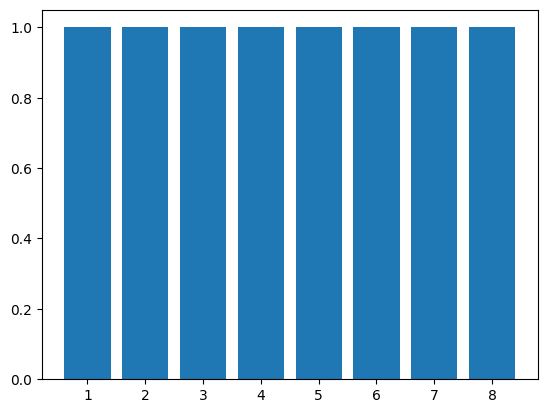

In [15]:
from matplotlib.pyplot import bar

labels = []
elements = []

for i in range(8):
    labels = labels + [i+1]
    elements = elements + [1]

# visualizar los valores de los elementos en la lista
bar(labels, elements)

Iteramos en un paso y visualizamos los valores de los elementos en la lista después de cada fase.

**1er paso - fase de consulta:**

### Cálculos paso a paso: Iteración 1

A continuación, mostraremos cómo evolucionan los valores de los elementos (amplitudes relativas) en un sistema de $N=8$ elementos, donde el elemento marcado es el índice 3. Inicialmente, todos los elementos valen 1.

**Estado inicial:**
* Valores: `[1, 1, 1, 1, 1, 1, 1, 1]`

**1. Fase de Consulta (Oráculo):**
El oráculo identifica el elemento marcado (índice 3) y multiplica su valor por -1.
* Nuevo estado esperado: `[1, 1, 1, -1, 1, 1, 1, 1]`

<BarContainer object of 8 artists>

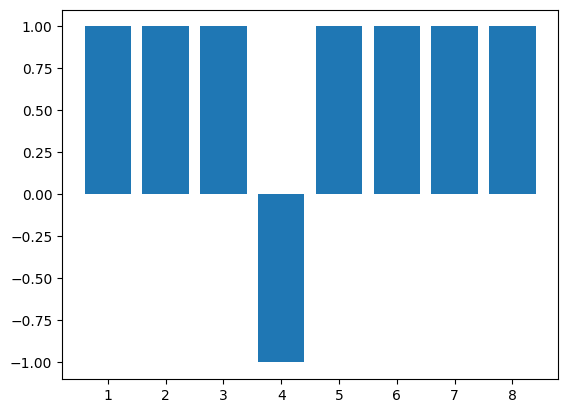

In [16]:
#
# 1er paso - consulta
#

# cambiar el signo del elemento marcado, es decir, multiplicarlo por -1
elements[3] = -1 * elements[3]                                                    # invertir el 4to elemento

# visualizar los valores de los elementos en la lista
bar(labels, elements)

**1er paso - fase de inversión:**

**Calculos Fase de Inversión sobre la media (Difusión):**
* **Cálculo de la media:** Sumamos los valores del estado actual y dividimos entre $N=8$.
  $\text{Suma} = 1 + 1 + 1 - 1 + 1 + 1 + 1 + 1 = 6$
  $\text{Media} = 6 / 8 = 0.75$
* **Reflexión sobre la media:** Para cada valor $x$, aplicamos $\text{nuevo_valor} = \text{Media} - (x - \text{Media})$.
  * Para los elementos no marcados ($x=1$): $\text{nuevo_valor} = 0.75 - (1 - 0.75) = 0.75 - 0.25 = 0.5$
  * Para el elemento marcado ($x=-1$): $\text{nuevo_valor} = 0.75 - (-1 - 0.75) = 0.75 - (-1.75) = 2.5$
* **Salida esperada:** `[0.5, 0.5, 0.5, 2.5, 0.5, 0.5, 0.5, 0.5]`

0.75


<BarContainer object of 8 artists>

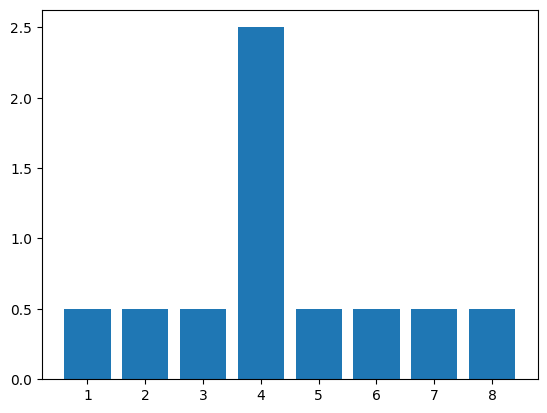

In [17]:
#
# 1er paso - inversión
#

# calcular la media de todos los valores

# luego refleja cada elemento sobre la media, por ejemplo:
# si la media es 0, entonces el reflejo de 3 es -3
# si la media es 1, entonces el reflejo de 3 es -1
# si la media es -1, entonces el reflejo de 3 es -5

# media de todos los valores
mean = sum(elements) / len(elements)
print(mean)

# reflexión sobre la media
for i in range(len(elements)):
    value = elements[i]
    new_value = mean - (value - mean)
    elements[i] = new_value

# visualizar los valores de los elementos en la lista
bar(labels, elements)

Iteramos un paso más y visualizamos los valores de los elementos en la lista después de cada fase.

**2do paso - fase de consulta:**

### Cálculos paso a paso: Iteración 2

Partimos de los valores obtenidos al finalizar la primera iteración:
* Valores actuales: `[0.5, 0.5, 0.5, 2.5, 0.5, 0.5, 0.5, 0.5]`

**1. Fase de Consulta (Oráculo):**
El oráculo vuelve a identificar el elemento marcado (índice 3) y multiplica su valor por -1.
* Nuevo estado esperado: `[0.5, 0.5, 0.5, -2.5, 0.5, 0.5, 0.5, 0.5]`

<BarContainer object of 8 artists>

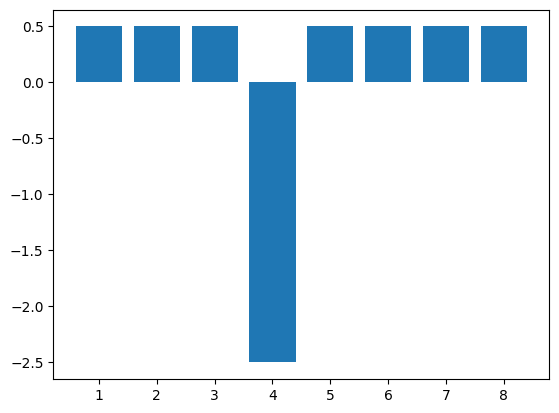

In [18]:
#
# 2do paso - consulta
#

# voltear el signo del elemento marcado (de nuevo)
elements[3] = -1 * elements[3]

# visualizar los valores de los elementos en la lista
bar(labels, elements)

**2do paso - fase de inversión:**

**Calculos fase de Inversión sobre la media (Difusión):**
* **Cálculo de la media:** Sumamos los valores del estado actual y dividimos entre $N=8$.
  $\text{Suma} = 7 \times (0.5) - 2.5 = 3.5 - 2.5 = 1$
  $\text{Media} = 1 / 8 = 0.125$
* **Reflexión sobre la media:** Para cada valor $x$, aplicamos $\text{nuevo_valor} = \text{Media} - (x - \text{Media})$.
  * Para los elementos no marcados ($x=0.5$): $\text{nuevo_valor} = 0.125 - (0.5 - 0.125) = 0.125 - 0.375 = -0.25$
  * Para el elemento marcado ($x=-2.5$): $\text{nuevo_valor} = 0.125 - (-2.5 - 0.125) = 0.125 - (-2.625) = 2.75$
* **Salida esperada:** `[-0.25, -0.25, -0.25, 2.75, -0.25, -0.25, -0.25, -0.25]`

0.125


<BarContainer object of 8 artists>

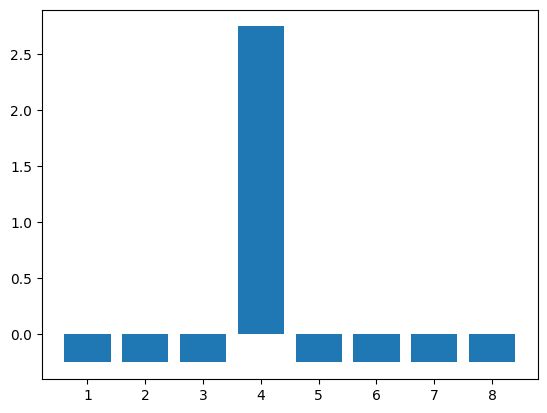

In [19]:
#
# 2do paso - inversión
#

# media de todos los valores
mean = sum(elements) / len(elements)
print(mean)

# reflexión sobre la media
for i in range(len(elements)):
    value = elements[i]
    new_value = mean - (value-mean)
    elements[i] = new_value

# visualizar los valores de los elementos en la lista
bar(labels, elements)

Repetimos tres pasos más y visualizamos los valores de los elementos en la lista al final.

### Cálculos paso a paso: Iteraciones 3, 4 y 5

Al ejecutar esta celda, el ciclo `for` realizará 3 iteraciones adicionales partiendo del estado en el que nos quedamos al finalizar el paso 2: `[-0.25, -0.25, -0.25, 2.75, -0.25, -0.25, -0.25, -0.25]`.

#### Iteración 3 (Vuelta 1 del ciclo)
* **1. Consulta:** El oráculo invierte el elemento marcado (índice 3), pasando a `-2.75`.
* **2. Inversión (Difusión):**
  * $\text{Suma} = 7 \times (-0.25) - 2.75 = -4.5 \rightarrow \text{Media} = -4.5 / 8 = -0.5625$
  * No marcados: $-0.5625 - (-0.25 - (-0.5625)) = -0.875$
  * Marcado: $-0.5625 - (-2.75 - (-0.5625)) = 1.625$
* **Salida de la iteración 3:** `[-0.875, -0.875, -0.875, 1.625, -0.875, -0.875, -0.875, -0.875]`

#### Iteración 4 (Vuelta 2 del ciclo)
Partimos del resultado anterior:
* **1. Consulta:** El elemento marcado pasa a `-1.625`.
* **2. Inversión (Difusión):**
  * $\text{Suma} = 7 \times (-0.875) - 1.625 = -7.75 \rightarrow \text{Media} = -7.75 / 8 = -0.96875$
  * No marcados: $-0.96875 - (-0.875 - (-0.96875)) = -1.0625$
  * Marcado: $-0.96875 - (-1.625 - (-0.96875)) = -0.3125$
* **Salida de la iteración 4:** `[-1.0625, -1.0625, -1.0625, -0.3125, -1.0625, -1.0625, -1.0625, -1.0625]`

#### Iteración 5 (Vuelta 3 del ciclo)
Partimos del resultado anterior:
* **1. Consulta:** El elemento marcado pasa a `0.3125`.
* **2. Inversión (Difusión):**
  * $\text{Suma} = 7 \times (-1.0625) + 0.3125 = -7.125 \rightarrow \text{Media} = -7.125 / 8 = -0.890625$
  * No marcados: $-0.890625 - (-1.0625 - (-0.890625)) = -0.71875$
  * Marcado: $-0.890625 - (0.3125 - (-0.890625)) = -2.09375$
* **Salida final tras el ciclo:** `[-0.71875, -0.71875, -0.71875, -2.09375, -0.71875, -0.71875, -0.71875, -0.71875]`

<BarContainer object of 8 artists>

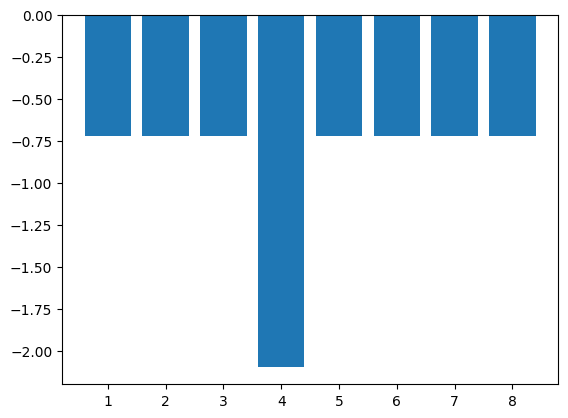

In [20]:
for i in range(3):
    # voltear el signo del elemento marcado
    elements[3] = -1 * elements[3]

    # media de todos los valores
    mean = sum(elements) / len(elements)

    # reflexión sobre la media
    for i in range(len(elements)):
        value = elements[i]
        new_value = mean - (value-mean)
        elements[i] = new_value

# visualizar los valores de los elementos en la lista
bar(labels, elements)

**¿Qué está pasando?**
Como pudimos notar, después de 5 pasos la amplitud del elemento marcado ha disminuido en comparación con su punto máximo (alrededor del segundo paso). Esto se debe a que el algoritmo de Grover funciona mediante rotaciones geométricas. Si iteramos demasiadas veces, nos "pasamos" de largo del ángulo óptimo y la probabilidad de encontrar la solución correcta vuelve a caer (a este fenómeno se le conoce como sobre-rotación).

---

### ¿Cuándo detenerse y cuántas iteraciones son necesarias?

Como observamos en la gráfica de 20 iteraciones, el algoritmo de Grover no consiste en repetir el proceso infinitamente. Al ser una rotación geométrica, cada iteración nos acerca a la respuesta correcta. Sin embargo, si giramos de más (fenómeno de **sobre-rotación**), las amplitudes de los elementos marcados comienzan a disminuir rápidamente, alcanzan un mínimo y vuelven a subir, formando un patrón cíclico.

Por lo tanto, **iterar el algoritmo requiere detenerse en el pico máximo de probabilidad.**

**Fórmula general:**
Si tenemos una lista de tamaño $N$ con un solo elemento marcado ($k=1$), el número óptimo de iteraciones para obtener la respuesta con alta probabilidad es:
$$ \approx \frac{\pi}{4}\sqrt{N} \text{ veces} $$

Si el problema tiene **múltiples elementos marcados ($k > 1$)**, la fórmula se ajusta a:
$$ \approx \frac{\pi}{4}\sqrt{\frac{N}{k}} \text{ veces} $$

*(Nota: Si se desconoce $k$, se pueden probar iteraciones basadas en diferentes valores posibles $\pi \frac{\sqrt{N/1}}{4}, \pi \frac{\sqrt{N/2}}{4}, \pi \frac{\sqrt{N/4}}{4} \dots$)*

**Comprobación con nuestro ejemplo (N=8):**
En el ejercicio que acabamos de realizar gráficamente, teníamos $N=8$ elementos y solo $k=1$ elemento marcado. Aplicando la fórmula:
$$ \text{Iteraciones} \approx \frac{\pi}{4}\sqrt{8} \approx \frac{3.1416}{4}(2.82) \approx 2.21 $$

Como no podemos hacer fracciones de pasos, redondeamos al entero más cercano. Esto nos confirma matemáticamente que **el número óptimo de pasos para nuestro ejemplo de 8 elementos era 2**, lo cual coincide perfectamente con el comportamiento que vimos en nuestras pruebas paso a paso.

### Preservación de longitud

Notemos que cada fase es un operador (función) que preserva la longitud.

¿Crees que los operadores de consulta e inversión son lineales? Más específicamente, ¿podemos representarlos en forma de matriz?

La respuesta para el operador de consulta es fácil ya que solo cambia el signo de los elementos marcados, por lo que su forma matricial es muy similar a una matriz de identidad que tiene $-1$ en algunas de las entradas diagonales.

Para el caso del ejemplo anterior, en donde marcamos el 4° elemento de una lista de 8, esta matriz sería:

$$\text{Operador consulta}=\pmatrix{
     1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
     0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 \\
     0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\
     0 & 0 & 0 & -1 & 0 & 0 & 0 & 0 \\
     0 & 0 & 0 & 0 & 1 & 0 & 0 & 0 \\
     0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 \\
     0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 \\
     0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 \\
     }$$

Ahora, necesitamos restringir la lista para que represente un **estado cuántico**.

Por ejemplo si $N=8$, la lista con esa cantidad de elementos, sería $[a,a,a,a,a,a,a,a]$.

Si es un estado cuántico, entonces su longitud debe ser $1$, por lo que se debe cumplir que: $ 8a^2 = 1 $ y entonces $a = \frac{1}{\sqrt{8}} = \frac{1}{2\sqrt{2}}$.

En general, cualquier lista con $N$ elementos es $ \Big[ \frac{1}{\sqrt{N}},\ldots,\frac{1}{\sqrt{N}} \Big] $.

### Fases

El operador en cada fase es unitario (lineal).

La matriz unitaria en la fase de consulta depende de la entrada, pero el operador unitario en la fase de inversión no depende de la entrada.

**En la fase de consulta**, las amplitudes de los elementos marcados cambian de signo.

**En la fase de inversión**, para cada amplitud $x$, el nuevo valor se calcula como: $media - (x - media) = 2 \, media - x $.

La media de un vector columna de tamaño $N$ se puede calcular multiplicándola por el siguiente vector renglón por la izquierda:

$$\pmatrix{ \frac{1}{N} ~~ \frac{1}{N} ~~ \cdots ~~ \frac{1}{N}}$$

Al considerar todos los elementos de la lista, nos deja con una matriz. La **matriz (*de difusión*)** para la segunda fase (*operador de inversión*) debe ser entonces:

$$D = 2 \pmatrix{
     \frac{1}{N} & \cdots & \frac{1}{N} \\
     \vdots & \ddots & \vdots \\
     \frac{1}{N} & \cdots & \frac{1}{N} \\
     }- I$$

### Derivación del número de iteraciones (Opcional)

El número de iteraciones en el algoritmo de Grover está dado por la fórmula aproximada:

$$k \approx \frac{\pi}{4} \sqrt{N}$$

Este número de iteraciones maximiza la probabilidad de encontrar el elemento marcado en una base de datos de tamaño $N$. Veamos paso a paso cómo se llega a esta fórmula.

$$ $$

1. Consideremos un sistema cuántico con $N$ estados base $|x\rangle$, donde $x = 0, 1, 2, \dots, N-1$. El estado inicial es una superposición uniforme de todos los estados es el siguiente:

$$|s\rangle = \frac{1}{\sqrt{N}} \sum_{x=0}^{N-1} |x\rangle$$

Supongamos que hay un solo elemento marcado, denotado como $|m\rangle$.

$$ $$

2. El algoritmo de Grover puede visualizarse como una rotación en un espacio de dos dimensiones, generado por los estados:

 - $|\alpha\rangle$: superposición de los estados no marcados
 - $|\beta\rangle = |m\rangle$: el estado marcado

Definimos:

$$|\alpha\rangle = \frac{1}{\sqrt{N-1}} \sum_{x \ne m} |x\rangle$$

Entonces, el estado inicial puede reescribirse como:

$$|s\rangle = \sqrt{\frac{N-1}{N}} |\alpha\rangle + \frac{1}{\sqrt{N}} |\beta\rangle$$

Si el ángulo entre $|s\rangle$ y $|\alpha\rangle$ es $\theta$, podemos reeescribir el estado como:

$$|s\rangle = \cos\theta |\alpha\rangle + \sin\theta |\beta\rangle$$

$$ $$

3. Ahora, calculamos el ángulo $\theta$ que determina la amplitud del estado marcado en la superposición inicial:

$$\sin \theta = \langle \beta | s \rangle = \frac{1}{\sqrt{N}}$$

Por lo tanto:

$$\theta = \arcsin\left( \frac{1}{\sqrt{N}} \right)$$

Para $N$ grande,

$$\theta \approx \frac{1}{\sqrt{N}}$$

Esto usando la aproximación $\sin\theta\approx \theta$ cuando $\theta$ es pequeño.

$$ $$

4. El operador de Grover, llamémoslo $G$, realiza una rotación en el plano $(|\alpha\rangle, |\beta\rangle)$ por un ángulo $2\theta$ en cada iteración:

$$G = (2|s\rangle\langle s| - I) \cdot (I - 2|m\rangle\langle m|)$$

Después de $k$ iteraciones, el estado del sistema es:

$$| \psi_k \rangle = \sin\left( (2k + 1) \theta \right) |\beta\rangle + \cos\left( (2k + 1) \theta \right) |\alpha\rangle$$

$$ $$

5. Queremos maximizar la probabilidad de medir el estado marcado $|\beta\rangle$, lo que corresponde a maximizar $\sin^2\left( (2k + 1) \theta \right)$.

La máxima probabilidad ocurre cuando:

$$(2k + 1) \theta = \frac{\pi}{2}$$

Solucionando para $k$:

$$k = \frac{\pi}{4\theta} - \frac{1}{2}$$

Para $N$ grande, podemos aproximar $\theta$ y simplificar:

$$k \approx \frac{\pi}{4} \sqrt{N} - \frac{1}{2}$$

Como el término $-\frac{1}{2}$ es insignificante para $N$ grande, lo ignoramos:

$$k \approx \frac{\pi}{4} \sqrt{N}$$

$$ $$

> La fórmula $\frac{\pi}{4} \sqrt{N}$ se obtiene al determinar el número de iteraciones necesarias para rotar el estado inicial hasta que la amplitud del estado marcado sea máxima. Este número de iteraciones proporciona una alta probabilidad de encontrar el elemento marcado al medir el estado final del sistema cuántico.

---
## Mini actividad. Implementación y análisis del algoritmo de Grover

**Objetivo:** Implementar Grover en Qiskit, visualizar su comportamiento durante 20 iteraciones y determinar cuándo detener el algoritmo.

**Duración:** 10 minutos.

Utiliza **3 cúbits de búsqueda** y marca únicamente el estado $|111\rangle$. Completa las siguientes cinco partes.




**A. Construcción del oráculo**

Construye un oráculo que invierta la fase del estado $|111\rangle$. Utiliza las compuertas Hadamard (H) y Toffoli (CCX) para implementar una CCZ.

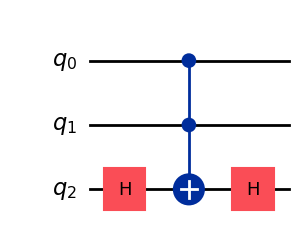

In [21]:
from qiskit import QuantumCircuit

n = 3

# Construye un oráculo que cambie la fase del estado |111>.
oraculo = QuantumCircuit(n)

# Implementa CCZ mediante la secuencia H, CCX y H.
oraculo.h(n - 1)
oraculo.ccx(0, 1, n - 1)
oraculo.h(n - 1)

display(oraculo.draw("mpl"))

**B. Construcción del difusor**

Implementa el difusor de Grover mediante la secuencia H–X–CCZ–X–H, utilizando el oráculo anterior como referencia para construir la compuerta CCZ.

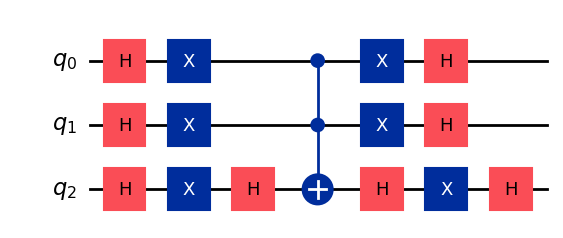

In [22]:
# Construye el difusor que realiza la inversión sobre la media.
difusor = QuantumCircuit(n)

# Aplica Hadamard y X a todos los cúbits.
difusor.h(range(n))
difusor.x(range(n))

# Implementa CCZ sobre los tres cúbits.
difusor.compose(oraculo, inplace=True)

# Aplica X y Hadamard para completar el difusor.
difusor.x(range(n))
difusor.h(range(n))

display(difusor.draw("mpl"))

**C. Implementación de Grover**

Construye una función `grover(k)` que prepare la superposición uniforme de los cúbits y aplique consecutivamente el oráculo y el difusor durante `k` iteraciones.

Utiliza `compose()` con `inplace=True` para incorporar ambos operadores al circuito.

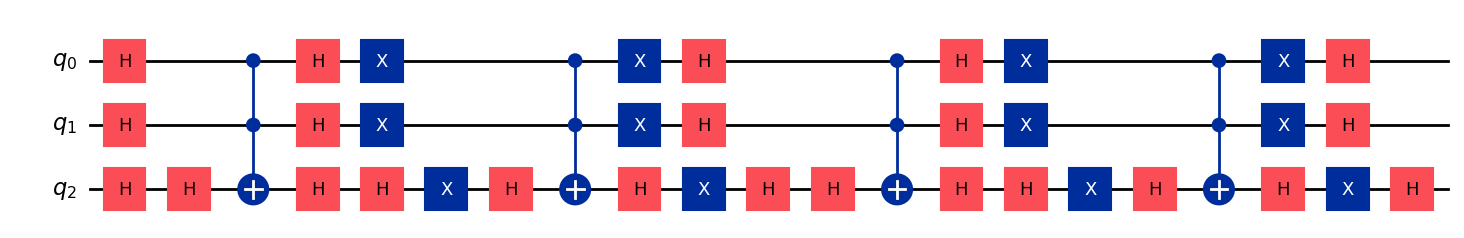

In [23]:
def grover(k):
    circuito = QuantumCircuit(n)

    # Prepara todos los cúbits en superposición uniforme.
    circuito.h(range(n))

    # Aplica el oráculo y el difusor durante k iteraciones.
    for _ in range(k):
        circuito.compose(oraculo, inplace=True)
        circuito.compose(difusor, inplace=True)

    return circuito

display(grover(2).draw("mpl"))

**D. Simulación de 20 iteraciones**

Ejecuta `grover(k)` desde 0 hasta 20 iteraciones. Utiliza `Statevector` para obtener la probabilidad de medir el estado $|111\rangle$ y representa su evolución mediante una gráfica.

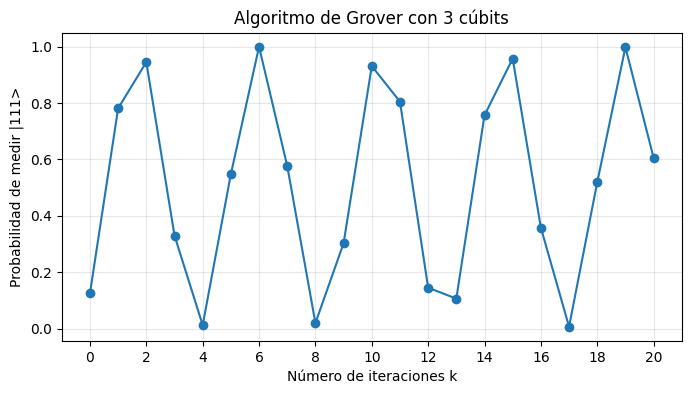

In [24]:
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector

probabilidades = []

# Ejecuta Grover con 0, 1, 2, ..., 20 iteraciones y registra la probabilidad de |111>.
for k in range(21):
    estado = Statevector(grover(k))
    probabilidades.append(estado.probabilities_dict().get("111", 0))

# Grafica la probabilidad de éxito frente al número de iteraciones.
plt.figure(figsize=(8, 4))
plt.plot(range(21), probabilidades, "o-")
plt.xticks(range(0, 21, 2))
plt.xlabel("Número de iteraciones k")
plt.ylabel("Probabilidad de medir |111>")
plt.title("Algoritmo de Grover con 3 cúbits")
plt.grid(alpha=0.3)
plt.show()

**E. Determinación del número de iteraciones**

Calcula el tamaño del espacio de búsqueda mediante $N=2^n$ y utiliza la aproximación:

$$
k\approx\frac{\pi}{4}\sqrt{\frac{N}{M}}
$$

donde $M$ es el número de estados marcados.

Comprueba la probabilidad de éxito al detener Grover con el número recomendado de iteraciones.

In [25]:
import numpy as np

# Calcula el espacio de búsqueda a partir del número de cúbits.
N = 2 ** n

# Define cuántos estados están marcados.
M = 1

# Calcula y redondea el número recomendado de iteraciones.
k_optimo = round(np.pi / 4 * np.sqrt(N / M))

# Ejecuta Grover con k_optimo y obtiene la probabilidad de |111>.
estado_final = Statevector(grover(k_optimo))
probabilidad = estado_final.probabilities_dict()["111"]

print("Espacio de búsqueda:", N)
print("Iteraciones recomendadas:", k_optimo)
print(f"Probabilidad de éxito: {probabilidad:.2%}")

Espacio de búsqueda: 8
Iteraciones recomendadas: 2
Probabilidad de éxito: 94.53%


**Pregunta final:** ¿Por qué no es conveniente aplicar siempre las 20 iteraciones de Grover?

**Respuesta:** Porque cada iteración rota el estado un ángulo $2\theta$ dentro del plano generado por los estados marcados y no marcados. La probabilidad de éxito es $\sin^2\big((2k+1)\theta\big)$, una función periódica de $k$: crece hasta un máximo (cerca de $k\approx\frac{\pi}{4}\sqrt{N/M}$) y después **disminuye** por la sobre-rotación, para volver a subir más adelante. Aplicar más iteraciones de las necesarias no mejora el resultado, desperdicia consultas al oráculo y puede dejar al algoritmo en un punto donde la probabilidad de éxito es muy baja.

---

<a id="2.2"></a>
## 2.2. Algoritmo de búsqueda de Grover

<div align="center"><img width="900px" style="display:block; margin-left: auto; margin-right: auto;" src="https://images.claudiazm.xyz/ecc26/GroverAmplitudeAmplification.gif"></div>

Supongamos que tenemos una lista de $N=2^n$ elementos, y uno de los elementos está marcado. La tarea es encontrar este elemento marcado.

Vamos a utilizar $n$ qubits. Al principio aplicamos Hadamard a cada qubit, por lo que ponemos nuestro estado cuántico en superposición. La amplitud de cada estado base $ \ket{0 \cdots 0}, \ldots, \ket{1 \cdots 1} $ se establece en $ \frac{1}{\sqrt{N}} $. Después de eso, iteramos el siguiente algoritmo varias veces:

- **Consulta**: aplicar un operador de consulta de Oracle a los qubits, lo que invierte el signo de la amplitud del estado que corresponde al elemento marcado.
- **Inversión**: aplicar la matriz de difusión, de modo que la amplitud de cada estado se refleja sobre la media de todas las amplitudes.

Veamos cómo podemos implementar las operaciones de consulta e inversión.

### Operación de consulta

#### Oráculo

Supongamos que existe una función $f:\{0,1\}^n \rightarrow \{0,1\}$ con las siguientes propiedades:

\begin{align*}
f(x)&=1 &\mbox{ si $x$ está marcado}\\
f(x)&=0 &\mbox{ en caso contrario}
\end{align*}

El algoritmo de Grover en realidad no busca una lista de elementos, pero dada la función $f$ con las propiedades anteriores, encuentra el elemento $x$ tal que $f(x)=1$.

$$ $$
Entonces accedemos a la lista consultando $f$, que se llama **oráculo** (oracle), también se le dice *caja negra*.

Normalmente, en el peor de los casos, tendríamos que consultar $f$ para todas las entradas posibles para encontrar $x$ que satisfaga $f(x)=1$, lo que implica una complejidad (de consulta) de $O(N)$.

El algoritmo de Grover puede realizar la misma tarea solo con $O\Big(\sqrt{N}\Big)$ consultas.

**Observación:** El algoritmo funciona si hay varios elementos marcados, pero asumimos que solo 1 elemento está marcado por simplicidad.

$$ $$
Aunque $f$ puede no ser reversible, se puede implementar de manera reversible utilizando la siguiente idea:

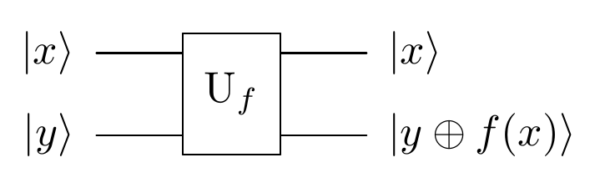

Aquí $U_f$, el operador cuántico correspondiente, se define de la siguiente manera, donde $\oplus$ denota la suma bit a bit módulo 2 ($XOR$).

$$U_f: \ket{y}\ket{x} \mapsto \ket{y \oplus f(x)}\ket{x} $$

Tengamos en cuenta que este mapeo es reversible. Cuando $\ket{y}=\ket{0}$, obtenemos exactamente $f(x)$ en el qubit ancilla.

#### Invertir el signo

En el resto de la discusión, asumiremos que tenemos un circuito cuántico que implementa el operador $U_f$. Se puede construir un operador que invierte el signo de la amplitud del estado correspondiente al elemento marcado $x$ usando **phase-kickback**.

Ahora supongamos que $\ket{y}=\ket{-} = \frac{1}{\sqrt{2}} (\ket{0} - \ket{1})$ e investiguemos el efecto del operador $U_f$.

\begin{align*}
U_f \ket{-}\ket{x} &= U_f \left( \frac{\ket{0}-\ket{1}}{\sqrt{2}} \right) \ket{x}\\
&= \frac{1}{\sqrt{2}} \left(U_f\ket{0}\ket{x}-U_f\ket{1}\ket{x}\right) \\
&= \frac{1}{\sqrt{2}} \left(\ket{f(x)\oplus 0}\ket{x} - \ket{f(x)\oplus 1}\ket{x}\right) \\
&= \frac{1}{\sqrt{2}}\left( \ket{f(x)}-\ket{f(x)\oplus 1} \right) \ket{x} \\
&= (-1)^{f(x)} \left( \frac{\ket{0}-\ket{1}}{\sqrt{2}} \right) \ket{x} \\
&= (-1)^{f(x)} \ket{-} \ket{x} \\
&= \ket{-} \;\;  \left[(-1)^{f(x)} \ket{x} \right] \\
\end{align*}

Así, tenemos la siguiente transformación:

$$ \ket{-}\ket{x} \xrightarrow{U_f} \ket{-} \;\;  \left[(-1)^{f(x)} \ket{x} \right] $$

Cuando $ f(x) = 1 $, vemos que una fase igual a $-1$ *se mueve al frente* (phase-kickback) del primer registro. Por lo tanto, al preparar el registro auxiliar en el estado $\ket{-}$ y aplicar $U_f$, obtenemos el efecto de cambio de signo deseado.

Tengamos en cuenta que incluso si no sabemos nada sobre $f$ (por eso se llama caja negra), podemos invertir el signo de la amplitud del elemento marcado haciendo una consulta a $f$ configurando el qubit ancilla (auxiliar) en $\ket{-}$.

<div class="alert alert-block alert-info">
<strong>Ejemplo</strong>:
    
Sea $N=4$. Implementar la fase de consulta y verificar la matriz unitaria del operador de consulta. Tener en cuenta que estamos interesados en la parte superior izquierda $4 \times 4$ de la matriz, ya que las partes restantes se deben al qubit ancilla.

¿Puedes adivinar el elemento marcado mirando la matriz unitaria?

Ahora usemos el retroceso de fase para invertir el signo del elemento marcado:

- [*preparación*] Establecer el qubit auxiliar en $\ket{-}$ aplicando $X$ y $H$.
- Aplicar el operador $U_f$
- [*finalización*] Regresar el qubit auxiliar.

In [26]:
def Uf(circuit, qreg):
	circuit.ccx(qreg[0], qreg[1], qreg[2])

<IPython.core.display.Latex object>

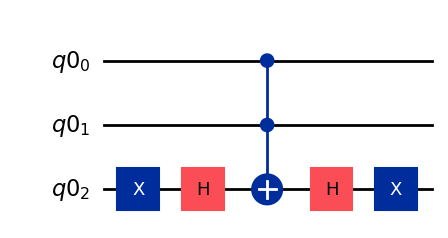

In [27]:
from qiskit import QuantumRegister, QuantumCircuit
from qiskit.quantum_info import Statevector, Operator, partial_trace
from qiskit.visualization import array_to_latex

qreg = QuantumRegister(3)
# No es necesario definir un registro clásico ya que no estamos midiendo

mycircuit = QuantumCircuit(qreg)

# registro ancilla
mycircuit.x(qreg[2])
mycircuit.h(qreg[2])

# aplicar oráculo
Uf(mycircuit, qreg)

# regresar el registro ancilla
mycircuit.h(qreg[2])
mycircuit.x(qreg[2])

op = Operator(mycircuit)
display(array_to_latex(op))

mycircuit.draw(output='mpl')

En el ejemplo anterior, observamos que el operador de consulta parece un operador identidad con una de las entradas igual a $-1$, que es responsable del cambio de signo.

$$\pmatrix{1 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & -1}$$

Al observar la matriz, podemos notar que el elemento marcado es $\ket{11}$. Tengamos en cuenta que, en general, no se puede echar un vistazo a la matriz correspondiente al operador de consulta y, por lo tanto, no es posible encontrar el elemento marcado después de una sola consulta.

### Ejemplos de oráculos cuánticos en Grover

Una vez definido el funcionamiento del oráculo de Grover, podemos construir diferentes implementaciones dependiendo del estado que deseamos encontrar.

Consideremos un sistema de dos cúbits, con cuatro estados posibles: $|00\rangle, |01\rangle, |10\rangle$ y $|11\rangle$.

A continuación, se muestran dos ejemplos de oráculos que identifican estados distintos. Aunque su construcción cambia, ambos cumplen el mismo propósito: marcar el estado buscado para que posteriormente el difusor de Grover amplifique su probabilidad de medición.

Oráculo que marca |11>


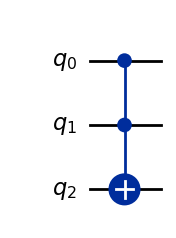

Oráculo que marca |10>


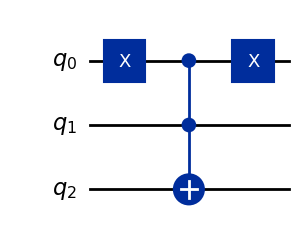

In [28]:
from qiskit import QuantumCircuit

# Ejemplo 1: Oráculo que marca |11>
def Uf_11(circuit, qreg, ancilla):
    circuit.ccx(qreg[0], qreg[1], ancilla)

# Ejemplo 2: Oráculo que marca |10>
def Uf_10(circuit, qreg, ancilla):
    circuit.x(qreg[0])
    circuit.ccx(qreg[0], qreg[1], ancilla)
    circuit.x(qreg[0])

# Mostrar el oráculo que marca |11>
circuito_11 = QuantumCircuit(3)
Uf_11(circuito_11, [0, 1], 2)

print("Oráculo que marca |11>")
display(circuito_11.draw("mpl"))

# Mostrar el oráculo que marca |10>
circuito_10 = QuantumCircuit(3)
Uf_10(circuito_10, [0, 1], 2)

print("Oráculo que marca |10>")
display(circuito_10.draw("mpl"))

En el primer circuito, la compuerta Toffoli identifica el estado $|11\rangle$, ya que se activa cuando ambos cúbits de control tienen valor 1.

En el segundo circuito, se agregan dos compuertas $X$ para invertir temporalmente el primer cúbit, permitiendo identificar el estado $|10\rangle$. La segunda compuerta $X$ restaura su valor original.

Estos ejemplos muestran cómo podemos adaptar un oráculo para marcar distintos estados, manteniendo el mismo principio de funcionamiento.

### Operador de inversión

Para implementar la operación de inversión (difusión), necesitaremos un qubit adicional (ancilla). Así es como implementamos el operador de inversión:

- [*preparación*] Establecer el qubit ancilla en $\ket{-}$ aplicando $X$ y $H$.
- Aplicar $H$ a todos los qubits distintos del ancilla.
- Aplicar $X$ a todos los qubits distintos del ancilla.
- Aplicar operador $NOT$ controlado múltiple, donde el qubit ancilla es el objetivo y todos los demás qubits se utilizan para controlar.
- Aplicar $X$ al qubit ancilla.
- Aplicar $X$ a todos los qubits distintos del ancilla.
- Aplicar $H$ a todos los qubits distintos del ancilla.
- [*finalización*] Regresar el qubit ancilla aplicando $X$ y $H$.

#### ¿Por qué se eligen estas compuertas?

Ahora intentemos entender por qué se eligen estas compuertas. Recordemos el operador de inversión:

$$D = 2 \pmatrix{
     \frac{1}{N} & \cdots & \frac{1}{N} \\
     \vdots & \ddots & \vdots \\
     \frac{1}{N} & \cdots & \frac{1}{N} \\
     } - I$$

Este operador también se denomina **operador de difusión**.

Recordemos que el operador de difusión se puede expresar como $D=2\ket{u}\bra{u}-I$, donde $\ket{u}=H^{\otimes n}\ket{0}^{\otimes n}$ es el vector de igual superposición. Simplemente denotaremos $\ket{0}^{\otimes n}$ con el ket $\ket{\mathbf{0}}$.

- Para empezar, expresemos $D$ de la siguiente manera:

\begin{align*}
D&=2\ket{u}\bra{u}-I \\
&=2H^{\otimes n}\ket{\mathbf{0}}\bra{\mathbf{0}}H^{\otimes n}- I \\
&=2H^{\otimes n}\ket{\mathbf{0}}\bra{\mathbf{0}}H^{\otimes n}-H^{\otimes n}H^{\otimes n}\\
&=H^{\otimes n} (2\ket{\mathbf{0}}\bra{\mathbf{0}}H^{\otimes n}-H^{\otimes n}) \\
&=H^{\otimes n} (2\ket{\mathbf{0}}\bra{\mathbf{0}}-I)H^{\otimes n}
\end{align*}

*Al observar esta expresión, queda claro por qué tenemos compuertas $H$ al principio y al final*

- Ahora veamos el efecto de aplicar $2\ket{\mathbf{0}}\bra{\mathbf{0}}-I$ a cualquier estado arbitrario.

$$(2\ket{\mathbf{0}}\bra{\mathbf{0}}-I) \ket{x} = 2\ket{\mathbf{0}}\braket{\mathbf{0}}{ x}-\ket{x}$$

Si $\ket{x}=\ket{\mathbf{0}}$, ya que $\braket{\mathbf{0}}{\mathbf{0}}=1$, entonces $2\ket{\mathbf{0}}\braket{\mathbf{0}}{\mathbf{0}}-\ket{\mathbf{0}} = 2\ket{\mathbf{0}}-\ket{\mathbf{0}} = \ket{\mathbf{0}}$.

Si $\ket{x}\neq \ket{\mathbf{0}}$, ya que $\braket{\mathbf{0}}{x}=0$, entonces $2\ket{\mathbf{0}}\braket{\mathbf{0}}{x}-\ket{x}= 2\ket{\mathbf{0}}\cdot 0 -\ket{x} = -\ket{x}$.

Por lo tanto, el efecto de $2\ket{\mathbf{0}}\bra{\mathbf{0}}-I$ es invertir la amplitud de cualquier estado excepto de $\ket{\mathbf{0}}$.

- Ahora revisemos cómo podemos implementar este operador. Definamos la función $g$ de la siguiente manera y dejemos que $U_g$ sea el operador correspondiente.

\begin{align*}
g(x)&=0 &\mbox{ si $x$ es $\ket{\mathbf{0}}$ }\\
g(x)&=1 &\mbox{ de lo contrario}
\end{align*}

Configuremos el qubit ancilla para que sea $\ket{-}$ y apliquemos el operador $U_g$

\begin{align*}
U_g \ket{-} \ket{x} &= (-1)^{g(x)} \ket{-} \ket{x}
\end{align*}

Tengamos en cuenta que $U_g$ invierte las amplitudes de los estados distintos de $\ket{\mathbf{0}}$ e implementa exactamente $2\ket{\mathbf{0}}\bra{\mathbf{0}}-I$.

- ¿Cómo implementar $U_g$?

Consideremos $g'$ que es exactamente lo opuesto a $g$.

\begin{align*}
g'(x)&=1 &\mbox{ si $x$ es $\ket{\mathbf{0}}$ }\\
g'(x)&=0 &\mbox{ en caso contrario},
\end{align*}

Para implementar $U_{g'}$, debemos regresar $1$ cuando $x$ es $\ket{\bf 0}$, es decir, debemos aplicar la compuerta $X$ al qubit ancilla cuando todos los qubits de entrada están en el estado $0$.

*Es por eso que primero aplicamos la compuerta $X$ a los qubits de control y luego aplicamos una compuerta multi-control $NOT$ donde el objetivo es el qubit ancilla. Luego, regresamos el estado de los qubits de control.*

Acabamos de obtener el efecto opuesto de $g$: el qubit ancilla se establece en $1$ si todos los qubits de entrada están en estado $0$.

*Por lo tanto, aplicamos la compuerta $X$ al qubit ancilla para que la salida sea $1$ cuando $x$ no es $\ket{\bf{0}}$ y la salida es $0$ en caso contrario.*

In [29]:
def inversion(circuit, quantum_reg, ancilla):

    # paso 1
    circuit.h(quantum_reg)

    # paso 2
    circuit.x(quantum_reg)

    # paso 3
    circuit.mcx(quantum_reg, ancilla)        # multi-cX gate -> params: control_qubits, target_qubit

    # paso 4
    circuit.x(quantum_reg)

    # paso 5
    circuit.x(ancilla)

    # paso 6
    circuit.h(quantum_reg)

### Circuito del difusor de Grover

Utilizando las operaciones descritas anteriormente, construimos el circuito del difusor para dos cúbits de entrada y un cúbit auxiliar. Este circuito implementa la inversión sobre la media de las amplitudes.

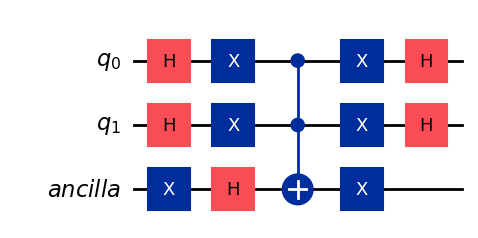

In [30]:
from qiskit import QuantumCircuit, QuantumRegister

# Crear los registros
q = QuantumRegister(2, "q")
ancilla = QuantumRegister(1, "ancilla")

circuito_difusor = QuantumCircuit(q, ancilla)

# Preparar el cúbit auxiliar en |->
circuito_difusor.x(ancilla[0])
circuito_difusor.h(ancilla[0])

# Aplicar la función del difusor
inversion(circuito_difusor, list(q), ancilla[0])

# Mostrar el circuito
display(circuito_difusor.draw("mpl"))

### Probar la búsqueda de Grover

Ahora estamos listos para probar las operaciones y ejecutar la búsqueda de Grover. Supongamos que hay $4$ elementos en la lista e intentemos encontrar el elemento marcado.

El operador $U_f$ marcará un elemento
    
¿Qué estado observas con más frecuencia?

In [31]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

def grover(U_f, n=2, iterations=1):

    qreg = QuantumRegister(n, 'x')
    ancilla = QuantumRegister(1, 'ancilla')
    creg = ClassicalRegister(n, 'medición')

    grover_circuit = QuantumCircuit(qreg, ancilla, creg)

    # paso inicial - igual superposición
    grover_circuit.h(qreg)

    # iniciar ancilla en |->
    grover_circuit.x(ancilla)
    grover_circuit.h(ancilla)
    grover_circuit.barrier()

    # Iteraciones de Grover
    for i in range(iterations):

        # consulta (query)
        U_f(grover_circuit, qreg, ancilla)
        grover_circuit.barrier()

        # inversión
        inversion(grover_circuit, qreg, ancilla)
        grover_circuit.barrier()


    # regresar el ancilla a |0>
    grover_circuit.h(ancilla)
    grover_circuit.x(ancilla)
    grover_circuit.barrier()

    grover_circuit.measure(qreg, creg)

    shots = 2500

    sampler = StatevectorSampler()                                  # crear objeto de tipo StatevectorSampler

    job_sampler = sampler.run([grover_circuit], shots=shots)
    conteos = job_sampler.result()[0].data.medición.get_counts()    # obtener los conteos, "medición" es el nombre del registro clásico

    # imprimir el resultado
    for outcome in conteos:
        print("El elemento", outcome, "es observado con probabilidad", conteos[outcome]/shots)

    display(grover_circuit.draw(output='mpl'))

El elemento 11 es observado con probabilidad 1.0


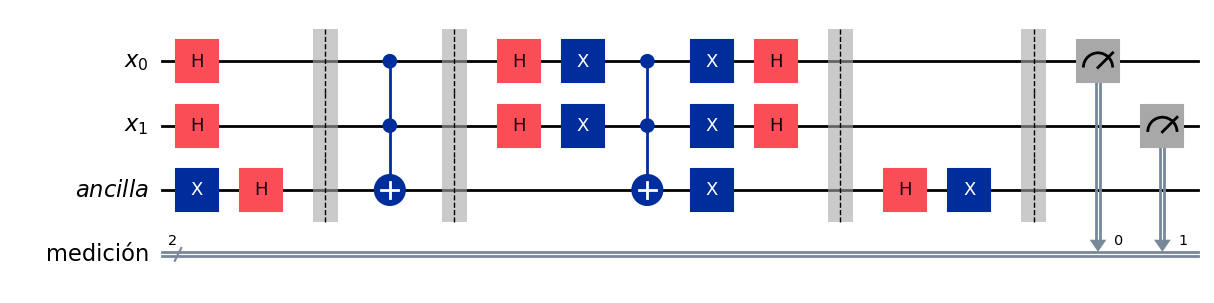

In [32]:
grover(Uf_11)

#### Otros oráculos

In [33]:
def Uf_10(circuit, qreg, ancilla):
    circuit.x(qreg[0])
    circuit.ccx(qreg[0], qreg[1], ancilla)
    circuit.x(qreg[0])

El elemento 10 es observado con probabilidad 1.0


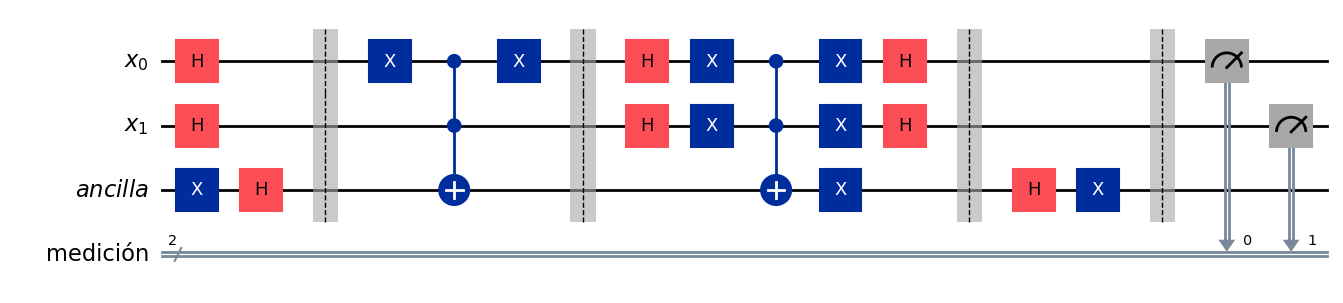

In [34]:
grover(Uf_10)

In [35]:
def Uf_01(circuit, qreg, ancilla):
    circuit.x(qreg[1])
    circuit.ccx(qreg[0], qreg[1], ancilla)
    circuit.x(qreg[1])

El elemento 01 es observado con probabilidad 1.0


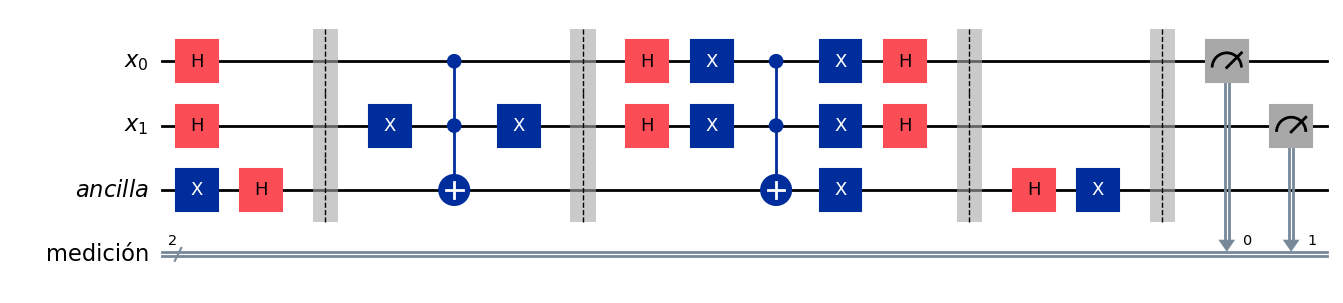

In [36]:
grover(Uf_01)

In [37]:
def Uf_00(circuit, qreg, ancilla):
    circuit.x(qreg[0])
    circuit.x(qreg[1])
    circuit.ccx(qreg[0], qreg[1], ancilla)
    circuit.x(qreg[0])
    circuit.x(qreg[1])

El elemento 00 es observado con probabilidad 1.0


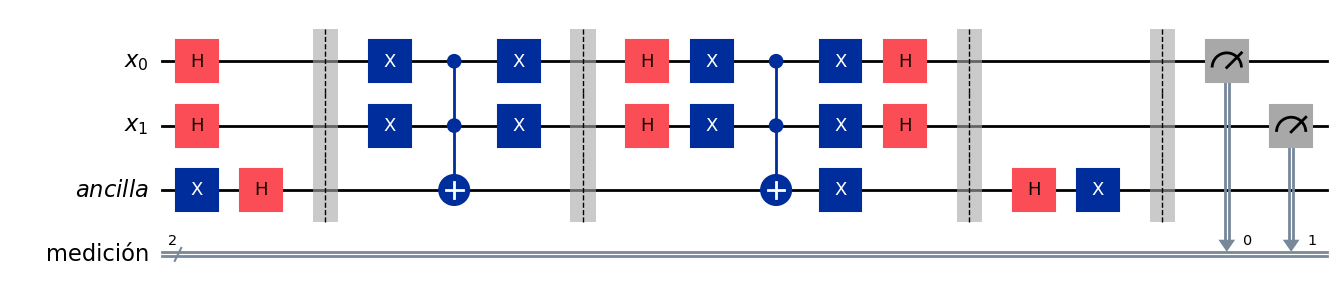

In [38]:
grover(Uf_00)

In [39]:
def Uf_001_010(circuit, qreg, ancilla):

    # 001
    circuit.x(qreg[1])
    circuit.x(qreg[2])
    circuit.mcx(qreg, ancilla)      # debido al uso de la compuerta MCX, es que se simula con 'StatevectorSampler' y no con 'BasicSimulator'
    circuit.x(qreg[1])
    circuit.x(qreg[2])

    # 010
    circuit.x(qreg[0])
    circuit.x(qreg[2])
    circuit.mcx(qreg, ancilla)
    circuit.x(qreg[0])
    circuit.x(qreg[2])

El elemento 010 es observado con probabilidad 0.4924
El elemento 001 es observado con probabilidad 0.5076


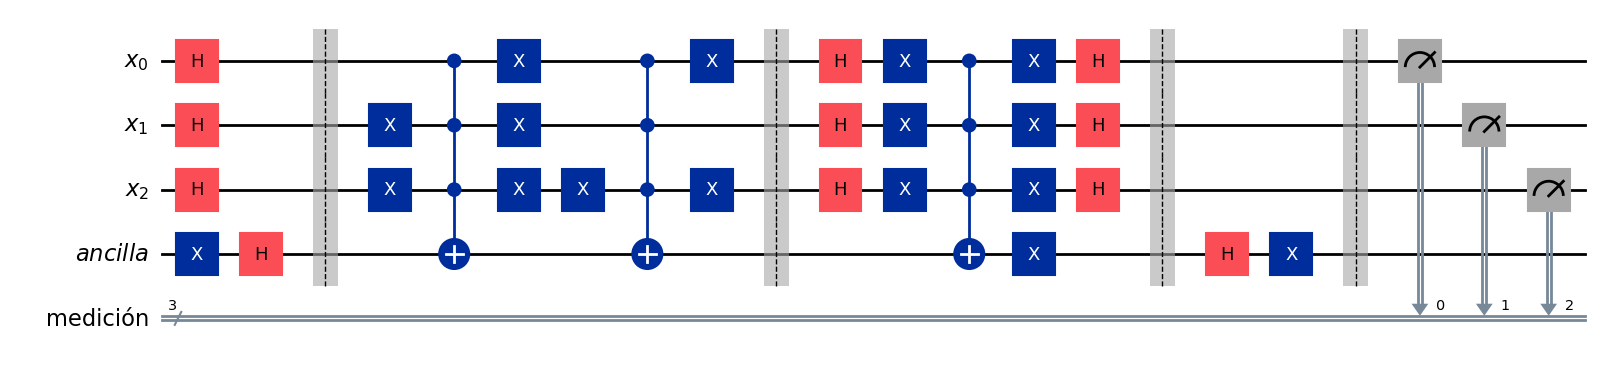

In [40]:
grover(Uf_001_010, n=3, iterations=1)

### Construcción del Algoritmo de Grover paso a paso

A continuación, construiremos el circuito cuántico para el algoritmo de Grover de manera progresiva. Lo dividiremos en las 3 fases principales: Inicialización, Oráculo y Difusor.

#### Paso 1: Inicialización
Para comenzar, necesitamos preparar nuestro sistema. El algoritmo requiere que todos los cúbits de datos (donde buscaremos la solución) comiencen en una superposición uniforme. Esto se logra aplicando una compuerta de Hadamard ($H$) a cada uno de ellos.

Además, preparamos un cúbit auxiliar (ancilla) en el estado $|-\rangle$. Este cúbit es fundamental porque permitirá que el oráculo aplique el "retroceso de fase" (*phase kickback*), cambiando el signo de la amplitud del elemento marcado. Para poner el ancilla en $|-\rangle$, le aplicamos una compuerta $X$ seguida de una $H$.

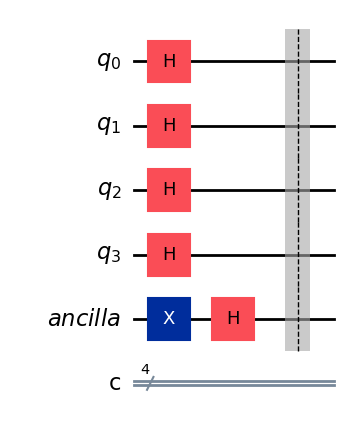

In [41]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

n = 4 # Número de cúbits de datos

# Definimos los registros
qreg = QuantumRegister(n, name='q')
ancilla = QuantumRegister(1, name='ancilla')
creg = ClassicalRegister(n, name='c')

# Creamos el circuito
grover_qc = QuantumCircuit(qreg, ancilla, creg)

# -- PASO 1: Inicialización --
# Superposición uniforme en los cúbits de datos
for i in range(n):
    grover_qc.h(qreg[i])

# Preparar el ancilla en el estado |->
grover_qc.x(ancilla)
grover_qc.h(ancilla)
grover_qc.barrier()

# Dibujamos el avance
grover_qc.draw("mpl")

#### Paso 2: Consulta al Oráculo ($U_f$)

Una vez que el sistema está en superposición, el siguiente paso es consultar el oráculo.
Como vimos en la teoría, el oráculo actúa como una "caja negra" que identifica el estado que estamos buscando. Al aplicarlo, la fase del estado marcado se invierte (se multiplica por -1) gracias al estado $\vert{}-\rangle$ de nuestro cúbit auxiliar, mientras que los demás estados permanecen intactos.

Para este paso, vamos a mandar llamar la función `oraculo_Uf(n)` que definimos al inicio de la práctica.

El oráculo buscará la cadena secreta: 0000


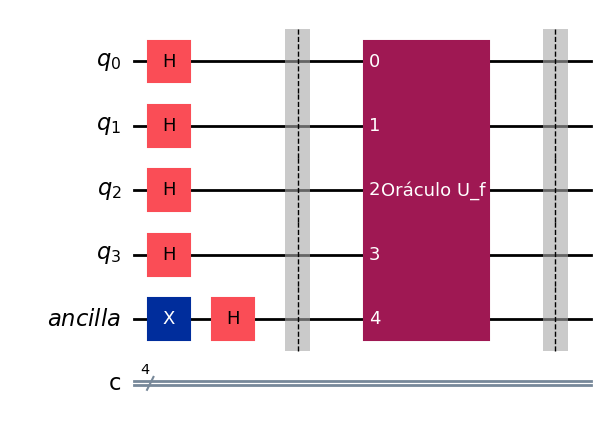

In [42]:
# -- PASO 2: Aplicación del Oráculo --
# Generamos el circuito del oráculo llamando a nuestra función
Uf_circ, cadena_secreta = oraculo_Uf(n)
print("El oráculo buscará la cadena secreta:", cadena_secreta)

# Convertimos el circuito del oráculo en una compuerta (gate) para que el dibujo se vea ordenado
oraculo_gate = Uf_circ.to_gate(label="Oráculo U_f")

# Agregamos la compuerta del oráculo a nuestro circuito principal
# Se aplica a todos los cúbits de datos + el ancilla
grover_qc.append(oraculo_gate, range(n + 1))
grover_qc.barrier()

# Dibujamos el avance
grover_qc.draw("mpl")

#### Paso 3: El Difusor (Inversión sobre la media)

Con la fase del estado marcado invertida, la probabilidad aún no ha cambiado al momento de medir. Para amplificar esta probabilidad necesitamos aplicar el **Difusor de Grover**.

Este operador realiza la "inversión sobre la media" geométrica que calculamos en los ejemplos anteriores. Se construye mediante los siguientes pasos en el circuito:
1. Aplicar compuertas $H$ a los cúbits de datos.
2. Aplicar compuertas $X$ a los cúbits de datos.
3. Aplicar una compuerta $Z$ multicontrolada (para marcar el estado $\vert{}00...0\rangle$). En Qiskit lo hacemos con un multicontrol-X (`mcx`) rodeado de compuertas $H$ en el cúbit objetivo.
4. Revertir las compuertas $X$ y $H$.

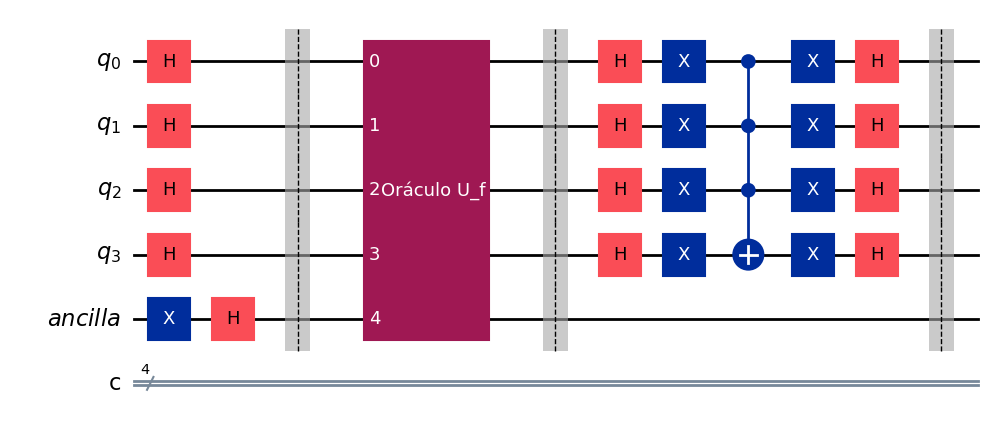

In [43]:
# -- PASO 3: El Difusor --

# 1. H a todos los cúbits de datos
for i in range(n):
    grover_qc.h(qreg[i])

# 2. X a todos los cúbits de datos
for i in range(n):
    grover_qc.x(qreg[i])

# 3. Compuerta Z multicontrolada
# Aplicamos H al último cúbit de datos, luego un CNOT múltiple, y otra vez H
#grover_qc.h(qreg[n-1])
grover_qc.mcx(list(range(n-1)), qreg[n-1])
#grover_qc.h(qreg[n-1])

# 4. Revertir compuertas X y H
for i in range(n):
    grover_qc.x(qreg[i])
for i in range(n):
    grover_qc.h(qreg[i])

grover_qc.barrier()

# Dibujamos el avance
grover_qc.draw("mpl")

#### Paso 4: Medición

¡Hemos completado una iteración entera del algoritmo de Grover! Si el número óptimo de iteraciones fuera mayor, repetiríamos los bloques del Oráculo y el Difusor.
Finalmente, medimos nuestros cúbits de datos para colapsar la superposición y obtener (con una probabilidad amplificada) la cadena secreta que el oráculo ocultaba.

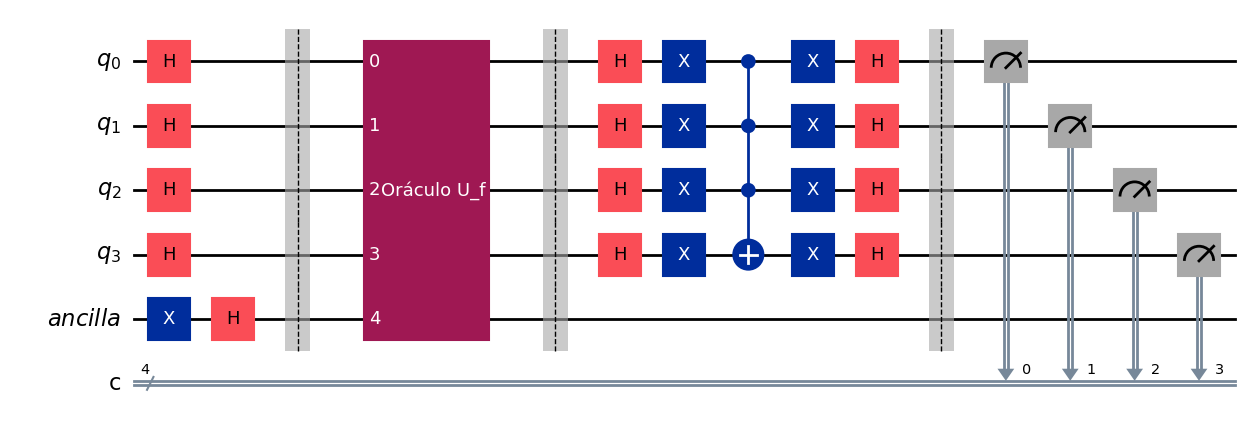

In [ ]:
# -- PASO 4: Medición --
# Medimos los cúbits de datos y los guardamos en el registro clásico
grover_qc.measure(qreg, creg)

# Dibujo final del circuito completo
grover_qc.draw("mpl")

In [ ]:
shots = 2500
sampler = StatevectorSampler()                                  # crear objeto de tipo StatevectorSampler

job_sampler = sampler.run([grover_qc], shots=shots)
conteos = job_sampler.result()[0].data.c.get_counts()    # obtener los conteos, "medición" es el nombre del registro clásico

    # imprimir el resultado
for outcome in conteos:
  print("El elemento", outcome, "es observado con probabilidad", conteos[outcome]/shots)

El elemento 1001 es observado con probabilidad 0.0624
El elemento 1111 es observado con probabilidad 0.066
El elemento 1101 es observado con probabilidad 0.0632
El elemento 0111 es observado con probabilidad 0.07
El elemento 1110 es observado con probabilidad 0.0672
El elemento 1011 es observado con probabilidad 0.0576
El elemento 0110 es observado con probabilidad 0.0708
El elemento 0010 es observado con probabilidad 0.062
El elemento 1000 es observado con probabilidad 0.0568
El elemento 0101 es observado con probabilidad 0.0576
El elemento 1100 es observado con probabilidad 0.0576
El elemento 0000 es observado con probabilidad 0.0556
El elemento 0011 es observado con probabilidad 0.0624
El elemento 1010 es observado con probabilidad 0.0592
El elemento 0100 es observado con probabilidad 0.0652
El elemento 0001 es observado con probabilidad 0.0664


<a id="2.3"></a>
## 2.3. Ejemplos de uso

### Problema del vendedor viajero (TSP)

El algoritmo de Grover no se limita a una lista. Puede ser aplicado a cualquier espacio de búsqueda siempre que se pueda construir dicha función $f$.

Consideremos la imagen a continuación. $A$, $B$, $C$ y $D$ son ciudades y los números representan la distancia entre ellas.

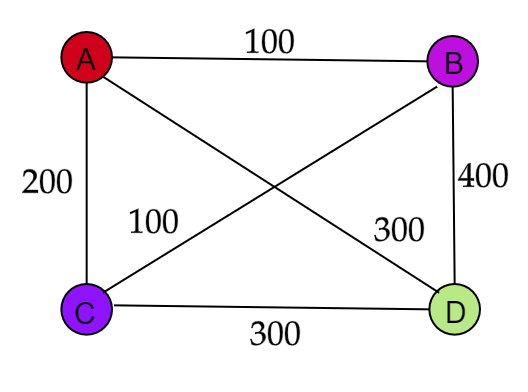

**Pregunta:** *Comenzando en $A$, ¿existe un camino de distancia $< 900$ que visite todas las ciudades exactamente una vez y regrese a $A$?*

Esto se conoce como la versión de decisión del Problema del Vendedor Viajero (Traveling Salesman Problem). En este ejemplo, el espacio de búsqueda consta de todas las rutas posibles, como $ABDCA$, $ACBDA$, $ABCDA$, etc. y nuestro objetivo es encontrar la ruta cuya distancia total sea $< 900$.

Revisemos $ABCDA$. La distancia total es $800$, lo que satisface la condición. Si deseamos diseñar $f$ para este problema, $f(\text{ABCDA})=1$ y $f(x)=0$ para todas las demás rutas.

**¿Cómo se puede construir tal $f$?**

Sumemos las distancias entre cada par de ciudades y asignemos $1$ si la distancia total es menor que $900$ y $0$ en caso contrario. Tengamos en cuenta que no necesitamos saber nada sobre la solución para implementar $f$.

Por supuesto, deberíamos poder diseñar tal $f$ en el entorno cuántico si deseamos aplicar la búsqueda de Grover y esto no siempre es una tarea fácil.

Por ejemplo, en este caso, se pueden hacer las asignaciones:

- $000$: $A \rightarrow B \rightarrow C \rightarrow D \rightarrow A$ (distancia 800, cumple la condición)
- $001$: $A \rightarrow B \rightarrow D \rightarrow C \rightarrow A$ (distancia 1000, no cumple)
- $010$: $A \rightarrow C \rightarrow B \rightarrow D \rightarrow A$ (distancia 1000, no cumple)
- $011$: $A \rightarrow C \rightarrow D \rightarrow B \rightarrow A$ (distancia 1000, no cumple)
- $100$: $A \rightarrow D \rightarrow B \rightarrow C \rightarrow A$ (distancia 1000, no cumple)
- $101$: $A \rightarrow D \rightarrow C \rightarrow B \rightarrow A$ (distancia 800, cumple la condición)

Por lo tanto, queremos que el oráculo marque los estados $|000\rangle$ y $|101\rangle$ (las rutas que cumplen con la condición de distancia < 900).

**¿Cómo ayuda la búsqueda de Grover en este problema?**

Verificar todas las rutas una por una es un procedimiento largo. Pero dada una ruta, podemos comprobar fácilmente si la distancia total cumple la condición. En lugar de comprobar todas las rutas una por una y consultar $f$ para cada ruta, basta con realizar $\sqrt{N}$ consultas si utilizamos la búsqueda de Grover.

Consulta este [enlace](https://github.com/quantum-challenge/2019/blob/master/problems/final/Final_en.ipynb) para ver otro ejemplo.

### Algunas aplicaciones

- **Logística y Distribución**: Esta es quizás la aplicación más directa del TSP. Se utiliza para optimizar las rutas de entrega de mercancías, desde paquetería hasta distribución de alimentos, minimizando la distancia total recorrida o el tiempo total de viaje. Esto se traduce en ahorros significativos en costos de combustible y tiempo.

- **Fabricación y Ensamblaje**: En entornos de producción, especialmente aquellos que involucran procesos de corte como la fabricación de ropa o el corte de metales, el TSP puede ayudar a minimizar el desplazamiento de las herramientas de corte, lo cual reduce el tiempo de producción y el desgaste de las máquinas.

- **Diseño de Circuitos Electrónicos**: El TSP se aplica en el diseño de circuitos impresos (PCB) y circuitos integrados (IC) para minimizar la longitud total de las conexiones eléctricas, lo que puede afectar directamente la velocidad y eficiencia del circuito.

- **Genómica**: En el secuenciamiento de ADN y otras formas de análisis genómico, el TSP ayuda a ordenar fragmentos de ADN en una secuencia que represente la disposición más probable en el genoma, facilitando su interpretación y análisis.

- **Astronomía**: Se utiliza para optimizar la secuencia de observaciones de los telescopios, con el fin de minimizar el tiempo de movimiento del telescopio entre diferentes puntos de observación en el cielo.

- **Programación de Tareas**: Aunque menos intuitivo, el TSP también se aplica en la programación de tareas donde se debe determinar el orden más eficiente para realizar actividades que tienen ciertas restricciones de precedencia y costos asociados.

$$ $$
$$ $$

### Otras aplicaciones del algoritmo de Grover

Además de los problemas de optimización como el vendedor viajero, el algoritmo de Grover puede utilizarse en otros problemas donde se busca encontrar una solución entre un gran número de posibilidades.

- **Criptografía:** En el campo de la seguridad informática, Grover puede utilizarse para acelerar la búsqueda exhaustiva de claves criptográficas. Esto permite reducir teóricamente el número de consultas necesarias para encontrar una clave correcta, aunque su implementación requiere una computadora cuántica con suficientes recursos.

- **Búsqueda en Bases de Datos No Estructuradas:** Cuando tenemos una gran cantidad de información sin un orden específico, Grover permite encontrar elementos que cumplan una determinada condición utilizando menos consultas que una búsqueda clásica convencional. Esto resulta útil en problemas donde no contamos con información adicional que facilite la búsqueda.

- **Problemas de Satisfacción de Restricciones:** En problemas donde debemos encontrar una combinación de valores que cumpla varias condiciones simultáneamente, Grover puede ayudar a identificar las soluciones válidas. Por ejemplo, en problemas de lógica o asignación de variables, podemos construir un oráculo que marque las combinaciones que satisfacen todas las restricciones.

### Problema del máximo corte (Max-Cut Problem)

Consideremos el siguiente grafo:

<div align="center"><img width="900px" style="display:block; margin-left: auto; margin-right: auto;" src="https://images.claudiazm.xyz/ecc26/MaxCutProblem.gif"></div>



El **problema de corte máximo** consiste en dividir los vértices de un grafo en dos conjuntos disjuntos (llamados particiones del corte), de modo que se maximice el número o el peso de las aristas que conectan ambos conjuntos. El tamaño del corte es el número de aristas que cruzan de un conjunto al otro.

**Visualización intuitiva:**
Una forma sencilla de entender esto es imaginar que coloreamos cada vértice del grafo con uno de dos colores (por ejemplo, azul o rojo). El objetivo es encontrar la combinación de colores que nos dé el número máximo de aristas conectando vértices de diferentes colores.



**Aplicación en Computación Cuántica:**
Para resolver esto con el algoritmo de Grover, nos centraremos en su versión de decisión. En lugar de pedirle al algoritmo que "encuentre el máximo" (lo cual es un problema de optimización), le daremos al oráculo una condición exacta: evaluar si una partición específica (representada por una cadena de bits como $x = 01010$, donde $0$ es el conjunto A y $1$ es el conjunto B) logra cortar un número de aristas mayor o igual a cierto valor deseado.

1.   Elemento de lista
2.   Elemento de lista



### Algunas aplicaciones

- **Diseño de Circuitos Electrónicos**: El problema de máximo corte se utiliza para el diseño y la optimización de circuitos VLSI (Very Large Scale Integration). En este contexto, se trata de minimizar el número de conexiones entre diferentes chips o diferentes partes de un chip, lo cual puede traducirse en un problema de máximo corte donde cada corte representa una disminución en el número de conexiones entre componentes.

- **Ciencia de Materiales**: En la física de materiales, especialmente en el estudio de sistemas magnéticos como los imanes, el problema del máximo corte puede usarse para modelar y optimizar la configuración de espines en un material, donde el objetivo es maximizar la diferencia entre conexiones de espines opuestos.

- **Clustering en Análisis de Datos**: El máximo corte también se puede aplicar en el clustering de datos para dividir un conjunto de datos en dos grupos de modo que las diferencias entre los grupos sean máximas. Esto es útil en análisis de redes sociales, biología computacional (por ejemplo, en la clasificación de genes o proteínas), y en la segmentación de mercados.

- **Planificación de Redes**: En la planificación de redes de telecomunicaciones o de transporte, el problema de máximo corte puede ayudar a determinar la forma más eficiente de segmentar una red para optimizar ciertos criterios de rendimiento o seguridad.

- **Finanzas**: En el sector financiero, el máximo corte puede ser empleado para la diversificación de portafolios, buscando minimizar el riesgo por medio de la separación de activos en diferentes categorías que maximicen la disimilitud en sus rendimientos.

$$ $$

<a id="4"></a>
# 3. Práctica 5

## **Instrucciones**

**A)** La tarea deberá entregarse en un **Jupyter Notebook (.ipynb) nuevo**. No se permite utilizar este mismo notebook. El notebook deberá incluir tu **nombre completo** y los ejercicios deberán estar **claramente separados y organizados**. El nombre del archivo deberá contener tu **nombre y apellidos**, o tu nombre acompañado de las **iniciales de tus apellidos**. Solo se aceptarán archivos `.ipynb`. Cualquier entrega en otro formato **no será calificada**. El archivo deberá subirse a **Google Classroom**.

**B)** La tarea es **estrictamente individual**. En caso de identificar trabajos realizados en conjunto o con contenido sustancialmente compartido, la tarea será anulada para las personas involucradas.

**C)** El uso de herramientas de **inteligencia artificial** estará fuertemente penalizado y se considerará en la calificación de cada inciso de acuerdo con el grado de uso. En caso de utilizar alguna, incluso de manera mínima, deberá indicarse explícitamente qué herramienta fue empleada, anexar los **prompts utilizados**, señalar los incisos en los que se utilizó y explicar brevemente la razón de su uso en cada caso. Cualquier uso de inteligencia artificial deberá ser **mostrado y justificado**. El uso de IA sin notificación llevará a la **anulación de la tarea**.

**D)** Los ejercicios marcados como **opcionales** otorgarán puntos extra sobre el **total de tareas**. No realizarlos **no restará puntos** de la calificación obtenida. Los puntos extra han sido **registrados y guardados**, por lo que no se verán reflejados directamente en la calificación de la tarea en la que fueron obtenidos. Serán considerados posteriormente para **sumarse al total de tareas correspondiente**.

Antes de continuar, revisa nuevamente todas las instrucciones de entrega. El incumplimiento de cualquiera de ellas puede afectar la calificación o invalidar la tarea.

<a id="4"></a>
# 4. Práctica 5

## Ejercicio 1. Algoritmo de Bernstein–Vazirani (5 puntos)

Implementa el algoritmo de Bernstein–Vazirani para recuperar cadenas binarias de **6 bits**, utilizando **6 cúbits de entrada** y un cúbit auxiliar `q0`.

### a) Construcción del oráculo (2 puntos)

Implementa una función `construir_oraculo(s)` que reciba una cadena binaria de 6 bits y construya el oráculo $U_f$, definido por:

$$f(x)=s\cdot x\pmod 2$$

La función debe permitir trabajar con **diferentes cadenas binarias sin modificar su implementación**. Muestra el circuito del oráculo para `s = "101101"`.

### b) Implementación del algoritmo (2 puntos)

Construye el circuito completo de Bernstein–Vazirani utilizando el oráculo anterior, incluyendo la preparación de estados y las mediciones correspondientes. Muestra el circuito completo para `s = "101101"`.

### c) Simulación y resultados (1 punto)

Simula en un **simulador cuántico de tu elección** el circuito de Bernstein–Vazirani para las siguientes cadenas binarias:

- `101101`
- `011010`
- `110011`

Presenta los resultados de las mediciones y comprueba que las tres cadenas se recuperan correctamente, sin modificar las funciones implementadas.

---

## Ejercicio 2. Algoritmo de Grover (5 puntos)

Implementa el algoritmo de Grover para un sistema de **6 cúbits de búsqueda**, considerando los siguientes estados marcados:

$$\vert{}001101\rangle,\quad \vert{}110010\rangle,\quad \vert{}101011\rangle$$

### a) Construcción del oráculo (2 puntos)

Implementa una función que construya el oráculo de Grover, invirtiendo la fase de los tres estados marcados. Muestra el circuito cuántico correspondiente.

### b) Construcción del difusor (2 puntos)

Implementa el operador de difusión de Grover para los 6 cúbits de búsqueda y muestra el circuito cuántico correspondiente.

### c) Implementación y simulación del algoritmo (1 punto)

Construye el circuito completo de Grover utilizando el oráculo y el difusor desarrollados anteriormente. Calcula y justifica el número apropiado de iteraciones.

Simula el circuito en un **simulador cuántico de tu elección** y presenta los resultados de las mediciones, identificando los tres estados marcados.

---

## Ejercicio extra. Búsqueda en una base de datos mediante Grover en PennyLane (1 punto)

Una institución cuenta con una base de datos de **16 equipos informáticos**, identificados mediante cadenas binarias de 4 bits. Cada equipo puede encontrarse en estado `Disponible` u `Ocupado`.

El objetivo es utilizar el algoritmo de **Grover en PennyLane** para localizar los equipos disponibles.

### Implementación y simulación (1 punto)

A partir de la base de datos proporcionada, implementa el algoritmo completo de Grover en PennyLane, construyendo el oráculo que marque los registros cuyo estado sea `Disponible` y el difusor correspondiente.

El oráculo debe construirse a partir de los datos, **sin introducir manualmente los identificadores de los equipos disponibles**.

Determina el número apropiado de iteraciones y simula el circuito mediante `default.qubit`. Muestra el circuito cuántico y las probabilidades de medición, identificando los equipos encontrados.

```python
equipos = {
    "0000": "Ocupado",
    "0001": "Disponible",
    "0010": "Ocupado",
    "0011": "Ocupado",
    "0100": "Disponible",
    "0101": "Ocupado",
    "0110": "Ocupado",
    "0111": "Ocupado",
    "1000": "Ocupado",
    "1001": "Ocupado",
    "1010": "Ocupado",
    "1011": "Ocupado",
    "1100": "Ocupado",
    "1101": "Ocupado",
    "1110": "Ocupado",
    "1111": "Ocupado"
}